# 부산신항 1~5부두 선석점유율과 평균 대기시간 분석

각 부두를 **직접 전처리 → 기록 연결 → 시뮬레이션 → 그래프**까지 분석합니다.

- 기간: **2022-01-01 이상, 2026-01-01 미만** (2022~2025년)
- 선석사용시간 배율: **80%~115%** (0.25%p씩 141개 시나리오)
- 두 결과: **최대 굴곡점**과 **초기 기울기 3배 지속 시작점**
- 그림: 왼쪽 **평균 대기시간**, 오른쪽 **평균 재항시간** (두 축 모두 일반 선형 축)


> 이 분석에서의 대기시간은 **관측 대기시간이 아니라** 선석별 작업시간을 변경하여 계산하는 대기행렬 시뮬레이션 값입니다. 임계점 역시 모형 기준의 후보입니다.

## 0. 공통 준비: 라이브러리 및 데이터 경로

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# 원래 프로젝트에서는 ../data 폴더 사용
DATA = Path('../data')

# 수업 자료처럼 CSV 인코딩 오류가 발생하면 다른 인코딩으로 읽기
def read_csv(filename):
    path = DATA / filename
    for encoding in ['utf-8-sig', 'cp949', 'euc-kr']:
        try:
            return pd.read_csv(path, encoding=encoding, low_memory=False)
        except UnicodeDecodeError:
            continue
    raise ValueError(f'인코딩을 확인하세요: {path}')

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 모든 부두에서 동일하게 사용할 분석 기간
period_start = pd.Timestamp('2022-01-01')
period_end = pd.Timestamp('2026-01-01')
period_hours = (period_end - period_start).total_seconds() / 3600

print('데이터 경로:', DATA.resolve())
print('분석 기간(종료일 미포함):', period_start, '~', period_end)

데이터 경로: C:\work\final_project\data
분석 기간(종료일 미포함): 2022-01-01 00:00:00 ~ 2026-01-01 00:00:00


### 공통 계산 방법

원본 노트북과 동일하게 **선박명 + 선석번호**가 같고 출항시각 차이가 24시간 이내인 기록을 연결합니다. 같은 PORTMIS 기록이 중복 연결되면 가장 가까운 출항시각의 행만 남깁니다.

**최대 굴곡점**: 점유율과 대기시간을 0/1로 정규화하여, 시작·끝을 잇는 직선에서 가장 많이 벌어지는 내부 지점 (전체 시나리오의 10-90% 위치 탐색).  
2차 미분 최댓값과는 다릅니다.

**3배 지속 시작점**: 이웃한 시나리오 간 `평균대기시간 변화 / 점유율 변화`를 구해 5구간 이동중앙값으로 완만하게 만든 뒤, 처음 40구간의 중앙 기울기보다 3배 이상인 구간이 **5개 연속**으로 나타나는 첫 위치입니다. 초기 40구간은 기준 기울기 계산용이므로 탐색은 40번째 구간부터 시작합니다.

**3시간 도달점**: 기존 노트북처럼 3시간 미만 마지막 행과 3시간 이상 첫 행 사이에서 보간합니다. 기간 내 미도달 시 표시하지 않습니다.

---

# 1부두 분석

## 1-1. 파일 읽기 및 원본 확인

이 부두의 터미널 CSV와 `record.csv`를 **직접 읽습니다.** 이전 부두에서 가공한 `ships`나 별도 결과 CSV를 이용하지 않습니다.

In [4]:
port1 = read_csv('port1.csv')
record1 = read_csv('record.csv')

print('port1:', port1.shape, 'record:', record1.shape)
display(port1.head())
display(record1.head())

port1: (2928, 7) record: (19989, 13)


,선석,선명,접안(예정)일시,출항(예정)일시,양하,적하,Shift
0,3,MSC JEWEL,2022-01-01 3:40,2022-01-03 5:00,1263,2905,2
1,1,COSCO SAO PAULO,2022-01-01 7:20,2022-01-02 7:00,402,1066,0
2,2,COPIAPO,2022-01-02 8:10,2022-01-04 12:00,1471,1998,108
3,1,MSC ELAINE,2022-01-02 9:10,2022-01-03 20:00,838,1281,2
4,3,MSC DESIREE,2022-01-03 7:20,2022-01-04 20:00,1139,1900,570


,호출부호,선명,입항횟수,총톤수,입항일시,출항일시,CIQ수속일자,수리일시,MRN 번호,계선장소,차항지,전출항지,재항시간
0,3FRF8,SONG YUN HE,2022.0,"16,737",2022-01-01 00:48:00,2022-01-03 01:52:00,2022-01-03 1:52,2022-01-03 15:58,22COHES152E,신항 5부두 3선석,QINGDAO,광양,49.066667
1,VRNA9,SEASPAN THAMES,2022.0,"112,967",2022-01-01 02:00:00,2022-01-02 17:43:00,2022-01-02 17:43,2022-01-03 11:18,22HLCU4202E,신항 3부두 4선석,VANCOUVER,SHANGHAI,39.716667
2,VRRP8,CMA CGM MUMBAI,2022.0,"112,967",2022-01-01 03:00:00,2022-01-02 04:06:00,2022-01-02 4:00,2022-01-03 11:22,22CMAL0030E,신항 5부두 2선석,MANZANILLO,SHANGHAI,25.100000
3,D5TL4,MSC JEWEL,2022.0,"140,976",2022-01-01 03:22:00,2022-01-03 05:00:00,2022-01-03 5:00,2022-01-03 11:19,22MSCU0004E,신항 1부두 3선석,MANZANILLO,HONG KONG,49.633333
4,A8YT7,MALIAKOS,2022.0,"41,391",2022-01-01 03:35:00,2022-01-01 16:45:00,2022-01-01 16:00,2022-01-03 11:07,22SMLME016E,신항 2부두 1선석,VANCOUVER,SHANGHAI,13.166667


## 1-2. 시각 변환과 선석사용시간 계산

접안시각과 터미널의 출항(예정)시각 차이를 **선석사용시간**으로 계산합니다. PORTMIS의 입항·출항시각도 `datetime`으로 변환합니다.

In [5]:
port = port1.copy()
rec = record1.copy()

port['접안시각'] = pd.to_datetime(port['접안(예정)일시'], format='mixed', errors='coerce')
port['선석종료시각'] = pd.to_datetime(port['출항(예정)일시'], format='mixed', errors='coerce')
rec['입항시각'] = pd.to_datetime(rec['입항일시'], format='mixed', errors='coerce')
rec['출항시각'] = pd.to_datetime(rec['출항일시'], format='mixed', errors='coerce')

port['선석사용시간'] = (
    port['선석종료시각'] - port['접안시각']
).dt.total_seconds() / 3600

print('선석사용시간 확인')
display(port[['선석', '접안시각', '선석종료시각', '선석사용시간']].head())

선석사용시간 확인


,선석,접안시각,선석종료시각,선석사용시간
0,3,2022-01-01 03:40:00,2022-01-03 05:00:00,49.333333
1,1,2022-01-01 07:20:00,2022-01-02 07:00:00,23.666667
2,2,2022-01-02 08:10:00,2022-01-04 12:00:00,51.833333
3,1,2022-01-02 09:10:00,2022-01-03 20:00:00,34.833333
4,3,2022-01-03 07:20:00,2022-01-04 20:00:00,36.666667


## 1-3. 선박명과 선석번호 정리

- 선박명에서 공백을 없애고 대문자로 변환합니다.
- 터미널 선석을 PORTMIS의 선석번호로 맞춥니다.


In [6]:
# 이번 부두 PORTMIS 기록만 선택
rec = rec[
    rec['계선장소'].astype('string').str.match(
        r'^신항 1부두 \d+선석$', na=False
    )
].copy()

port['연결선명'] = (
    port['선명'].astype('string').str.upper().str.replace(r'\s+', '', regex=True)
)
rec['연결선명'] = (
    rec['선명'].astype('string').str.upper().str.replace(r'\s+', '', regex=True)
)

# 'T1' 형식과 '1' 형식을 모두 처리 (T 문자가 없어도 됨)
port['원본선석번호'] = pd.to_numeric(
    port['선석'].astype('string').str.extract(r'(\d+)')[0], errors='coerce'
)
port['선석번호'] = port['원본선석번호']
rec['선석번호'] = pd.to_numeric(
    rec['계선장소'].astype('string').str.extract(r'(\d+)선석')[0], errors='coerce'
)

# 숫자로 통일한 다음 문자열로 맞춤 (예: 1.0 → '1')
port['선석번호'] = port['선석번호'].astype('Int64').astype('string')
rec['선석번호'] = rec['선석번호'].astype('Int64').astype('string')
rec['기록번호'] = range(len(rec))

print('터미널 선석번호 대응')
display(port[['선석', '원본선석번호', '선석번호']].drop_duplicates().sort_values('선석번호'))
print('PORTMIS 선석번호별 건수')
display(rec['선석번호'].value_counts().sort_index())

터미널 선석번호 대응


,선석,원본선석번호,선석번호
1,1,1,1
2,2,2,2
0,3,3,3


PORTMIS 선석번호별 건수


선석번호
1    1105
2     983
3     840
Name: count, dtype: int64[pyarrow]

## 1-4. `merge_asof()`로 두 자료 연결

선박명·선석번호가 같고 **출항시각 차이가 24시간 이내인 기록 중 가장 가까운 것**을 연결합니다. 연결 실패한 행과 중복 행 수를 확인합니다.

In [7]:
port_before = len(port)
port = port.dropna(subset=['선석번호', '연결선명', '접안시각', '선석종료시각']).copy()
rec = rec.dropna(subset=['선석번호', '연결선명', '입항시각', '출항시각']).copy()

ships = pd.merge_asof(
    port.sort_values('선석종료시각'),
    rec[['연결선명', '선석번호', '입항시각', '출항시각', '기록번호']].sort_values('출항시각'),
    left_on='선석종료시각',
    right_on='출항시각',
    by=['연결선명', '선석번호'],
    direction='nearest',
    tolerance=pd.Timedelta(hours=24)
)

unmatched = ships['기록번호'].isna().sum()
ships = ships.dropna(subset=['기록번호']).copy()
ships['출항시각차이'] = (ships['선석종료시각'] - ships['출항시각']).abs()
ships = ships.sort_values('출항시각차이')
duplicated = ships['기록번호'].duplicated().sum()
ships = ships.drop_duplicates('기록번호').copy()

print('시각/이름/선석 누락으로 제외:', port_before - len(port))
print('연결 실패:', unmatched)
print('동일 기록번호 중복 제외:', duplicated)
print('연결 및 중복 제거 후:', len(ships))
display(ships[['선석번호', '입항시각', '접안시각', '선석종료시각', '출항시각']].head())

시각/이름/선석 누락으로 제외: 0
연결 실패: 44
동일 기록번호 중복 제외: 0
연결 및 중복 제거 후: 2884


,선석번호,입항시각,접안시각,선석종료시각,출항시각
2927,1,2025-12-31 12:30:00,2025-12-31 12:30:00,2026-01-01 12:58:00,2026-01-01 12:58:00
2346,1,2025-02-08 11:55:00,2025-02-08 11:55:00,2025-02-09 11:58:00,2025-02-09 11:58:00
2345,1,2025-02-07 02:56:00,2025-02-07 02:56:00,2025-02-08 10:37:00,2025-02-08 10:37:00
2344,2,2025-02-05 12:14:00,2025-02-05 12:46:00,2025-02-08 04:00:00,2025-02-08 04:00:00
2343,3,2025-02-05 13:58:00,2025-02-05 13:58:00,2025-02-07 13:00:00,2025-02-07 13:00:00


## 1-5. 시간 조건 확인 및 분석 기간 선택

`접안전시간 ≥ 0`, `선석사용시간 > 0`, `재항시간 > 0` 조건을 모두 만족해야 사용합니다. 이번에는 **제외 데이터도 별도로 확인**합니다.

In [8]:
ships['접안전시간'] = (
    ships['접안시각'] - ships['입항시각']
).dt.total_seconds() / 3600
ships['재항시간'] = (
    ships['출항시각'] - ships['입항시각']
).dt.total_seconds() / 3600

bad = (
    (ships['접안전시간'] < 0)
    | (ships['선석사용시간'] <= 0)
    | (ships['재항시간'] <= 0)
    | ships[['접안전시간', '선석사용시간', '재항시간']].isna().any(axis=1)
)
out_ships1 = ships[bad].copy()
cp_ships1 = ships[~bad].copy()

# 2022~2025년 입항 기록만 선택
sim_data1 = cp_ships1[
    (cp_ships1['입항시각'] >= period_start)
    & (cp_ships1['입항시각'] < period_end)
].sort_values('입항시각').copy()

print('시간 조건 제외:', len(out_ships1))
print('시간 조건 통과:', len(cp_ships1))
print('2022~2025년 최종 분석:', len(sim_data1))
print('최종 분석 선석:', sorted(sim_data1['선석번호'].dropna().unique().tolist()))
display(sim_data1[['입항시각', '접안시각', '선석번호', '선석사용시간', '접안전시간', '재항시간']].head())

시간 조건 제외: 69
시간 조건 통과: 2815
2022~2025년 최종 분석: 2815
최종 분석 선석: ['1', '2', '3']


,입항시각,접안시각,선석번호,선석사용시간,접안전시간,재항시간
1,2022-01-01 03:22:00,2022-01-01 03:40:00,3,49.333333,0.300000,49.633333
0,2022-01-01 07:10:00,2022-01-01 07:20:00,1,23.666667,0.166667,23.750000
2,2022-01-02 08:58:00,2022-01-02 09:10:00,1,34.833333,0.200000,34.950000
4,2022-01-03 07:10:00,2022-01-03 07:20:00,3,36.666667,0.166667,37.166667
5,2022-01-03 21:57:00,2022-01-03 22:20:00,1,30.666667,0.383333,31.133333


## 1-6. 시뮬레이션 입력 준비

입항시각을 분석 시작부터 경과한 시간으로 바꾸고, 출항 추가시간을 계산합니다. 각 선석에 배가 차례대로 도착했을 때의 대기시간을 계산합니다.

In [9]:
sim_data1['입항경과시간'] = (
    sim_data1['입항시각'] - period_start
).dt.total_seconds() / 3600
sim_data1['출항추가시간'] = (
    sim_data1['출항시각'] - sim_data1['선석종료시각']
).dt.total_seconds().div(3600).clip(lower=0)

배정자료 = list(
    sim_data1[
        ['입항경과시간', '선석번호', '선석사용시간', '출항추가시간']
    ].itertuples(index=False, name=None)
)

# 연결에 성공한 선석만 시뮬레이션에 사용
선석목록 = sorted(int(v) for v in sim_data1['선석번호'].unique())
선석수 = len(선석목록)
assert 선석수 > 0 and len(배정자료) > 0, '분석에 사용할 선박/선석이 없습니다.'

# 원래 노트북과 같은 대기행렬 계산
def simulate(scale):
    free = {berth: 0.0 for berth in 선석목록}
    waits = []
    residences = []
    occupied = 0.0

    for arrival, berth, service, exit_time in 배정자료:
        berth = int(berth)
        work = service * scale
        start = max(arrival, free[berth])
        finish = start + work
        free[berth] = finish

        waits.append(start - arrival)
        residences.append(finish + exit_time - arrival)
        occupied += max(0, min(finish, period_hours) - max(start, 0))

    return {
        '사용시간배율': scale,
        '점유율': occupied / (선석수 * period_hours) * 100,
        '평균대기시간': sum(waits) / len(waits),
        '평균재항시간': sum(residences) / len(residences)
    }

baseline1 = simulate(1.0)
print('사용시간 100%의 결과')
display(pd.DataFrame([baseline1]).round(2))

사용시간 100%의 결과


,사용시간배율,점유율,평균대기시간,평균재항시간
0,1.0,75.79,1.19,29.62


## 1-7. 80~115% 시나리오 계산

수업자료처럼 **0.0025(0.25%p)** 간격으로 141번 계산합니다. 다른 CSV에서 결과를 불러오지 않습니다.

In [10]:
scales = [0.80 + i * 0.0025 for i in range(141)]
results1 = pd.DataFrame([simulate(scale) for scale in scales])

print('시뮬레이션 건수:', len(results1))
display(results1.head())
display(results1.tail())

시뮬레이션 건수: 141


,사용시간배율,점유율,평균대기시간,평균재항시간
0,0.8000,60.640625,0.591891,23.351841
1,0.8025,60.830071,0.596654,23.427427
2,0.8050,61.019479,0.601439,23.503035
3,0.8075,61.208887,0.606226,23.578644
4,0.8100,61.398295,0.611012,23.654254


,사용시간배율,점유율,평균대기시간,평균재항시간
136,1.1400,86.269683,14.537703,46.929552
137,1.1425,86.444927,15.383708,47.846379
138,1.1450,86.619974,16.244451,48.777945
139,1.1475,86.795021,17.112500,49.716817
140,1.1500,86.970068,18.015591,50.690731


## 1-8. 최대 굴곡점과 초기 기울기 3배 지속 시작점

**최대 굴곡점:** 정규화한 곡선과 양 끝점을 이은 직선 사이의 최대 간격.  
**3배 지속 시작점:** 초기 기울기(첫 40구간 중앙값)의 3배 이상인 기울기가 연속 5구간 유지되는 첫 위치.  
두 기준을 계산한 뒤, 최초 노트북의 **평균 대기 3시간 도달점**도 함께 계산합니다.

In [11]:
x = results1['점유율'].to_numpy()
y = results1['평균대기시간'].to_numpy()

# 1) 곡선의 최대 굴곡점: 직선에서 가장 크게 벌어진 지점
x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (y - y.min()) / (y.max() - y.min())
distance = x_norm - y_norm
candidate = np.arange(max(2, int(len(x) * 0.1)), min(len(x)-2, int(len(x) * 0.9)))
bend_idx = int(candidate[np.argmax(distance[candidate])])

# 2) 이웃한 시나리오의 기울기를 계산하고 5구간 이동중앙값 사용
slope = np.diff(y) / np.diff(x)
smooth_slope = pd.Series(slope).rolling(5, center=True, min_periods=1).median().to_numpy()
initial_slope = float(np.median(smooth_slope[:40]))

onset_idx = None
for i in range(40, len(smooth_slope)-4):
    if (smooth_slope[i:i+5] >= initial_slope * 3).all():
        onset_idx = i
        break

# 3) 평균 대기시간이 3시간에 도달하는 지점 (원본 노트북의 보간 방식)
below = results1[results1['평균대기시간'] < 3]
above = results1[results1['평균대기시간'] >= 3]
occupancy_at_3h = np.nan
if len(below) > 0 and len(above) > 0:
    p1 = below.iloc[-1]
    p2 = above.iloc[0]
    if p1['사용시간배율'] < p2['사용시간배율']:
        ratio = (3 - p1['평균대기시간']) / (p2['평균대기시간'] - p1['평균대기시간'])
        occupancy_at_3h = p1['점유율'] + ratio * (p2['점유율'] - p1['점유율'])

print(f'최대 굴곡점: {x[bend_idx]:.2f}% / 대기 {y[bend_idx]:.2f}시간')
if onset_idx is not None:
    print(f'기울기 3배 지속 시작: {x[onset_idx]:.2f}% / 대기 {y[onset_idx]:.2f}시간')
else:
    print('기울기 3배 지속 시작: 범위 안에서 찾지 못함')
print('평균 대기 3시간 도달점:', round(occupancy_at_3h, 2) if pd.notna(occupancy_at_3h) else '범위 내 미도달')

summary1 = {
    '부두': '1부두',
    '최종 분석 건수': len(sim_data1),
    '기본 점유율': baseline1['점유율'],
    '최대 굴곡점': x[bend_idx],
    '기울기 3배 시작점': x[onset_idx] if onset_idx is not None else np.nan,
    '대기 3시간 도달점': occupancy_at_3h
}

최대 굴곡점: 80.90% / 대기 2.14시간
기울기 3배 지속 시작: 78.44% / 대기 1.37시간
평균 대기 3시간 도달점: 81.87


## 1-9. 그래프 출력

이전 형식과 동일하게 **좌: 대기시간 / 우: 재항시간**으로 그립니다. 왼쪽에만 두 분석 지점과 3시간 점선을 추가합니다. **일반 선형 축**입니다.

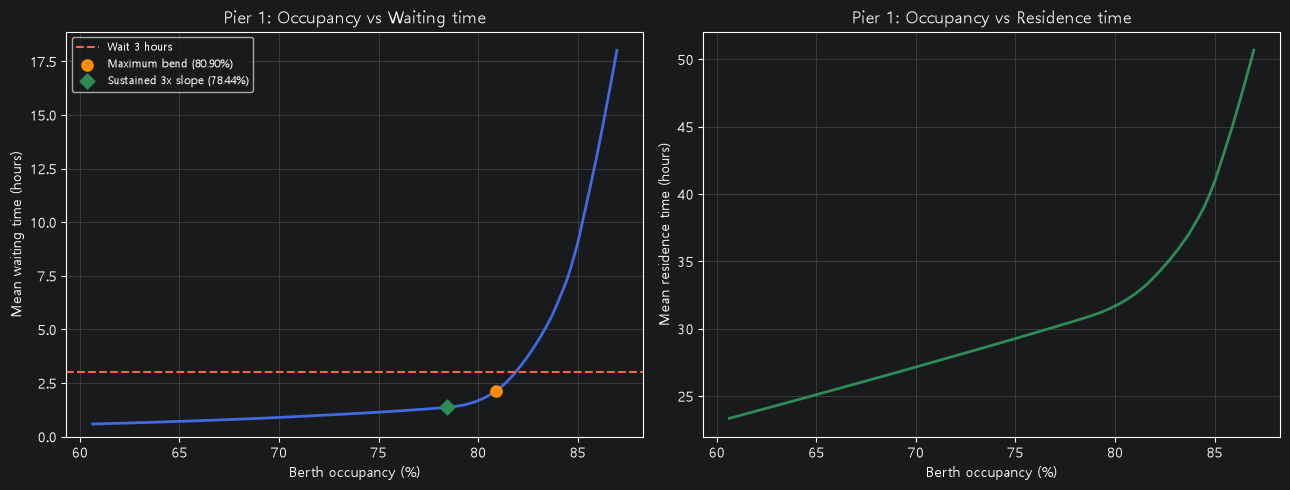

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(results1['점유율'], results1['평균대기시간'],
             color='royalblue', linewidth=2)
axes[0].axhline(3, color='tomato', linestyle='--', label='Wait 3 hours')
axes[0].scatter(x[bend_idx], y[bend_idx], color='darkorange', s=65,
                label=f'Maximum bend ({x[bend_idx]:.2f}%)', zorder=5)
if onset_idx is not None:
    axes[0].scatter(x[onset_idx], y[onset_idx], marker='D', color='seagreen',
                    s=58, label=f'Sustained 3x slope ({x[onset_idx]:.2f}%)', zorder=6)
axes[0].set_title('Pier 1: Occupancy vs Waiting time')
axes[0].set_xlabel('Berth occupancy (%)')
axes[0].set_ylabel('Mean waiting time (hours)')
axes[0].set_ylim(bottom=0)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(results1['점유율'], results1['평균재항시간'],
             color='seagreen', linewidth=2)
axes[1].set_title('Pier 1: Occupancy vs Residence time')
axes[1].set_xlabel('Berth occupancy (%)')
axes[1].set_ylabel('Mean residence time (hours)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---

# 2부두 분석

## 2-1. 파일 읽기 및 원본 확인

이 부두의 터미널 CSV와 `record.csv`를 **직접 읽습니다.** 이전 부두에서 가공한 `ships`나 별도 결과 CSV를 이용하지 않습니다.

In [13]:
port2 = read_csv('port2.csv')
record2 = read_csv('record.csv')

print('port2:', port2.shape, 'record:', record2.shape)
display(port2.head())
display(record2.head())

port2: (10943, 7) record: (19989, 13)


,선석,선명,접안(예정)일시,출항(예정)일시,양하,적하,Shift
0,7,ATHOS,2019-12-31 6:00,2020-01-01 12:58,1632,1038,464
1,4,NORTHERN JUVENILE,2019-12-31 6:52,2020-01-01 10:24,288,1818,222
2,6,NYK ISABEL,2019-12-31 11:00,2020-01-01 8:00,1000,896,0
3,5,EMIRATES WAFA,2019-12-31 12:05,2020-01-01 7:20,805,689,56
4,8,MOL TRIUMPH,2019-12-31 20:25,2020-01-02 19:00,3844,1617,222


,호출부호,선명,입항횟수,총톤수,입항일시,출항일시,CIQ수속일자,수리일시,MRN 번호,계선장소,차항지,전출항지,재항시간
0,3FRF8,SONG YUN HE,2022.0,"16,737",2022-01-01 00:48:00,2022-01-03 01:52:00,2022-01-03 1:52,2022-01-03 15:58,22COHES152E,신항 5부두 3선석,QINGDAO,광양,49.066667
1,VRNA9,SEASPAN THAMES,2022.0,"112,967",2022-01-01 02:00:00,2022-01-02 17:43:00,2022-01-02 17:43,2022-01-03 11:18,22HLCU4202E,신항 3부두 4선석,VANCOUVER,SHANGHAI,39.716667
2,VRRP8,CMA CGM MUMBAI,2022.0,"112,967",2022-01-01 03:00:00,2022-01-02 04:06:00,2022-01-02 4:00,2022-01-03 11:22,22CMAL0030E,신항 5부두 2선석,MANZANILLO,SHANGHAI,25.100000
3,D5TL4,MSC JEWEL,2022.0,"140,976",2022-01-01 03:22:00,2022-01-03 05:00:00,2022-01-03 5:00,2022-01-03 11:19,22MSCU0004E,신항 1부두 3선석,MANZANILLO,HONG KONG,49.633333
4,A8YT7,MALIAKOS,2022.0,"41,391",2022-01-01 03:35:00,2022-01-01 16:45:00,2022-01-01 16:00,2022-01-03 11:07,22SMLME016E,신항 2부두 1선석,VANCOUVER,SHANGHAI,13.166667


## 2-2. 시각 변환과 선석사용시간 계산

접안시각과 터미널의 출항(예정)시각 차이를 **선석사용시간**으로 계산합니다. PORTMIS의 입항·출항시각도 `datetime`으로 변환합니다.

In [14]:
port = port2.copy()
rec = record2.copy()

port['접안시각'] = pd.to_datetime(port['접안(예정)일시'], format='mixed', errors='coerce')
port['선석종료시각'] = pd.to_datetime(port['출항(예정)일시'], format='mixed', errors='coerce')
rec['입항시각'] = pd.to_datetime(rec['입항일시'], format='mixed', errors='coerce')
rec['출항시각'] = pd.to_datetime(rec['출항일시'], format='mixed', errors='coerce')

port['선석사용시간'] = (
    port['선석종료시각'] - port['접안시각']
).dt.total_seconds() / 3600

print('선석사용시간 확인')
display(port[['선석', '접안시각', '선석종료시각', '선석사용시간']].head())

선석사용시간 확인


,선석,접안시각,선석종료시각,선석사용시간
0,7,2019-12-31 06:00:00,2020-01-01 12:58:00,30.966667
1,4,2019-12-31 06:52:00,2020-01-01 10:24:00,27.533333
2,6,2019-12-31 11:00:00,2020-01-01 08:00:00,21.000000
3,5,2019-12-31 12:05:00,2020-01-01 07:20:00,19.250000
4,8,2019-12-31 20:25:00,2020-01-02 19:00:00,46.583333


## 2-3. 선박명과 선석번호 정리

- 선박명에서 공백을 없애고 대문자로 변환합니다.
- 터미널 선석을 PORTMIS의 선석번호로 맞춥니다.
- **2부두:** 터미널 4→PORTMIS 1, …, 터미널 9→PORTMIS 6. 원본 PORTMIS에 6선석이 없다면 9선석은 연결되지 않습니다.


In [15]:
# 이번 부두 PORTMIS 기록만 선택
rec = rec[
    rec['계선장소'].astype('string').str.match(
        r'^신항 2부두 \d+선석$', na=False
    )
].copy()

port['연결선명'] = (
    port['선명'].astype('string').str.upper().str.replace(r'\s+', '', regex=True)
)
rec['연결선명'] = (
    rec['선명'].astype('string').str.upper().str.replace(r'\s+', '', regex=True)
)

# 'T1' 형식과 '1' 형식을 모두 처리 (T 문자가 없어도 됨)
port['원본선석번호'] = pd.to_numeric(
    port['선석'].astype('string').str.extract(r'(\d+)')[0], errors='coerce'
)
port['선석번호'] = port['원본선석번호'] - 3
rec['선석번호'] = pd.to_numeric(
    rec['계선장소'].astype('string').str.extract(r'(\d+)선석')[0], errors='coerce'
)

# 숫자로 통일한 다음 문자열로 맞춤 (예: 1.0 → '1')
port['선석번호'] = port['선석번호'].astype('Int64').astype('string')
rec['선석번호'] = rec['선석번호'].astype('Int64').astype('string')
rec['기록번호'] = range(len(rec))

print('터미널 선석번호 대응')
display(port[['선석', '원본선석번호', '선석번호']].drop_duplicates().sort_values('선석번호'))
print('PORTMIS 선석번호별 건수')
display(rec['선석번호'].value_counts().sort_index())

터미널 선석번호 대응


,선석,원본선석번호,선석번호
1,4,4,1
3,5,5,2
2,6,6,3
0,7,7,4
4,8,8,5
669,9,9,6


PORTMIS 선석번호별 건수


선석번호
1    1625
2    1439
3    1249
4    1102
5    1007
Name: count, dtype: int64[pyarrow]

## 2-4. `merge_asof()`로 두 자료 연결

선박명·선석번호가 같고 **출항시각 차이가 24시간 이내인 기록 중 가장 가까운 것**을 연결합니다. 연결 실패한 행과 중복 행 수를 확인합니다.

In [16]:
port_before = len(port)
port = port.dropna(subset=['선석번호', '연결선명', '접안시각', '선석종료시각']).copy()
rec = rec.dropna(subset=['선석번호', '연결선명', '입항시각', '출항시각']).copy()

ships = pd.merge_asof(
    port.sort_values('선석종료시각'),
    rec[['연결선명', '선석번호', '입항시각', '출항시각', '기록번호']].sort_values('출항시각'),
    left_on='선석종료시각',
    right_on='출항시각',
    by=['연결선명', '선석번호'],
    direction='nearest',
    tolerance=pd.Timedelta(hours=24)
)

unmatched = ships['기록번호'].isna().sum()
ships = ships.dropna(subset=['기록번호']).copy()
ships['출항시각차이'] = (ships['선석종료시각'] - ships['출항시각']).abs()
ships = ships.sort_values('출항시각차이')
duplicated = ships['기록번호'].duplicated().sum()
ships = ships.drop_duplicates('기록번호').copy()

print('시각/이름/선석 누락으로 제외:', port_before - len(port))
print('연결 실패:', unmatched)
print('동일 기록번호 중복 제외:', duplicated)
print('연결 및 중복 제거 후:', len(ships))
display(ships[['선석번호', '입항시각', '접안시각', '선석종료시각', '출항시각']].head())

시각/이름/선석 누락으로 제외: 0
연결 실패: 4594
동일 기록번호 중복 제외: 0
연결 및 중복 제거 후: 6349


,선석번호,입항시각,접안시각,선석종료시각,출항시각
6963,4,2023-11-03 04:26:00,2023-11-03 04:54:00,2023-11-04 02:22:00,2023-11-04 02:22:00
6796,1,2023-09-30 07:18:00,2023-10-01 06:49:00,2023-10-01 15:58:00,2023-10-01 15:58:00
6799,1,2023-10-01 17:50:00,2023-10-01 17:50:00,2023-10-02 14:18:00,2023-10-02 14:18:00
6800,4,2023-10-01 09:52:00,2023-10-01 10:10:00,2023-10-02 14:32:00,2023-10-02 14:32:00
6802,5,2023-10-01 09:00:00,2023-10-01 09:12:00,2023-10-02 21:15:00,2023-10-02 21:15:00


## 2-5. 시간 조건 확인 및 분석 기간 선택

`접안전시간 ≥ 0`, `선석사용시간 > 0`, `재항시간 > 0` 조건을 모두 만족해야 사용합니다. 이번에는 **제외 데이터도 별도로 확인**합니다.

In [17]:
ships['접안전시간'] = (
    ships['접안시각'] - ships['입항시각']
).dt.total_seconds() / 3600
ships['재항시간'] = (
    ships['출항시각'] - ships['입항시각']
).dt.total_seconds() / 3600

bad = (
    (ships['접안전시간'] < 0)
    | (ships['선석사용시간'] <= 0)
    | (ships['재항시간'] <= 0)
    | ships[['접안전시간', '선석사용시간', '재항시간']].isna().any(axis=1)
)
out_ships2 = ships[bad].copy()
cp_ships2 = ships[~bad].copy()

# 2022~2025년 입항 기록만 선택
sim_data2 = cp_ships2[
    (cp_ships2['입항시각'] >= period_start)
    & (cp_ships2['입항시각'] < period_end)
].sort_values('입항시각').copy()

print('시간 조건 제외:', len(out_ships2))
print('시간 조건 통과:', len(cp_ships2))
print('2022~2025년 최종 분석:', len(sim_data2))
print('최종 분석 선석:', sorted(sim_data2['선석번호'].dropna().unique().tolist()))
display(sim_data2[['입항시각', '접안시각', '선석번호', '선석사용시간', '접안전시간', '재항시간']].head())

시간 조건 제외: 1773
시간 조건 통과: 4576
2022~2025년 최종 분석: 4576
최종 분석 선석: ['1', '2', '3', '4', '5']


,입항시각,접안시각,선석번호,선석사용시간,접안전시간,재항시간
3583,2022-01-01 03:35:00,2022-01-01 03:35:00,1,13.200000,0.000000,13.166667
3589,2022-01-01 12:00:00,2022-01-01 12:18:00,4,45.216667,0.300000,45.516667
3585,2022-01-01 13:40:00,2022-01-01 13:42:00,2,27.183333,0.033333,27.250000
3587,2022-01-01 13:50:00,2022-01-01 13:50:00,3,30.200000,0.000000,30.166667
3586,2022-01-01 17:10:00,2022-01-01 17:35:00,5,25.416667,0.416667,25.833333


## 2-6. 시뮬레이션 입력 준비

입항시각을 분석 시작부터 경과한 시간으로 바꾸고, 출항 추가시간을 계산합니다. 각 선석에 배가 차례대로 도착했을 때의 대기시간을 계산합니다.

In [18]:
sim_data2['입항경과시간'] = (
    sim_data2['입항시각'] - period_start
).dt.total_seconds() / 3600
sim_data2['출항추가시간'] = (
    sim_data2['출항시각'] - sim_data2['선석종료시각']
).dt.total_seconds().div(3600).clip(lower=0)

배정자료 = list(
    sim_data2[
        ['입항경과시간', '선석번호', '선석사용시간', '출항추가시간']
    ].itertuples(index=False, name=None)
)

# 연결에 성공한 선석만 시뮬레이션에 사용
선석목록 = sorted(int(v) for v in sim_data2['선석번호'].unique())
선석수 = len(선석목록)
assert 선석수 > 0 and len(배정자료) > 0, '분석에 사용할 선박/선석이 없습니다.'

# 원래 노트북과 같은 대기행렬 계산
def simulate(scale):
    free = {berth: 0.0 for berth in 선석목록}
    waits = []
    residences = []
    occupied = 0.0

    for arrival, berth, service, exit_time in 배정자료:
        berth = int(berth)
        work = service * scale
        start = max(arrival, free[berth])
        finish = start + work
        free[berth] = finish

        waits.append(start - arrival)
        residences.append(finish + exit_time - arrival)
        occupied += max(0, min(finish, period_hours) - max(start, 0))

    return {
        '사용시간배율': scale,
        '점유율': occupied / (선석수 * period_hours) * 100,
        '평균대기시간': sum(waits) / len(waits),
        '평균재항시간': sum(residences) / len(residences)
    }

baseline2 = simulate(1.0)
print('사용시간 100%의 결과')
display(pd.DataFrame([baseline2]).round(2))

사용시간 100%의 결과


,사용시간배율,점유율,평균대기시간,평균재항시간
0,1.0,58.76,1.23,23.76


## 2-7. 80~115% 시나리오 계산

수업자료처럼 **0.0025(0.25%p)** 간격으로 141번 계산합니다. 다른 CSV에서 결과를 불러오지 않습니다.

In [19]:
scales = [0.80 + i * 0.0025 for i in range(141)]
results2 = pd.DataFrame([simulate(scale) for scale in scales])

print('시뮬레이션 건수:', len(results2))
display(results2.head())
display(results2.tail())

시뮬레이션 건수: 141


,사용시간배율,점유율,평균대기시간,평균재항시간
0,0.8000,47.007516,0.661580,18.695619
1,0.8025,47.154382,0.666735,18.757060
2,0.8050,47.301248,0.671896,18.818508
3,0.8075,47.448115,0.677077,18.879975
4,0.8100,47.594981,0.682305,18.941489


,사용시간배율,점유율,평균대기시간,평균재항시간
136,1.1400,66.972274,3.843130,29.532093
137,1.1425,67.118893,3.951146,29.696396
138,1.1450,67.265512,4.060351,29.861887
139,1.1475,67.412131,4.171085,30.028906
140,1.1500,67.558750,4.283661,30.197769


## 2-8. 최대 굴곡점과 초기 기울기 3배 지속 시작점

**최대 굴곡점:** 정규화한 곡선과 양 끝점을 이은 직선 사이의 최대 간격.  
**3배 지속 시작점:** 초기 기울기(첫 40구간 중앙값)의 3배 이상인 기울기가 연속 5구간 유지되는 첫 위치.  
두 기준을 계산한 뒤, 최초 노트북의 **평균 대기 3시간 도달점**도 함께 계산합니다.

In [20]:
x = results2['점유율'].to_numpy()
y = results2['평균대기시간'].to_numpy()

# 1) 곡선의 최대 굴곡점: 직선에서 가장 크게 벌어진 지점
x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (y - y.min()) / (y.max() - y.min())
distance = x_norm - y_norm
candidate = np.arange(max(2, int(len(x) * 0.1)), min(len(x)-2, int(len(x) * 0.9)))
bend_idx = int(candidate[np.argmax(distance[candidate])])

# 2) 이웃한 시나리오의 기울기를 계산하고 5구간 이동중앙값 사용
slope = np.diff(y) / np.diff(x)
smooth_slope = pd.Series(slope).rolling(5, center=True, min_periods=1).median().to_numpy()
initial_slope = float(np.median(smooth_slope[:40]))

onset_idx = None
for i in range(40, len(smooth_slope)-4):
    if (smooth_slope[i:i+5] >= initial_slope * 3).all():
        onset_idx = i
        break

# 3) 평균 대기시간이 3시간에 도달하는 지점 (원본 노트북의 보간 방식)
below = results2[results2['평균대기시간'] < 3]
above = results2[results2['평균대기시간'] >= 3]
occupancy_at_3h = np.nan
if len(below) > 0 and len(above) > 0:
    p1 = below.iloc[-1]
    p2 = above.iloc[0]
    if p1['사용시간배율'] < p2['사용시간배율']:
        ratio = (3 - p1['평균대기시간']) / (p2['평균대기시간'] - p1['평균대기시간'])
        occupancy_at_3h = p1['점유율'] + ratio * (p2['점유율'] - p1['점유율'])

print(f'최대 굴곡점: {x[bend_idx]:.2f}% / 대기 {y[bend_idx]:.2f}시간')
if onset_idx is not None:
    print(f'기울기 3배 지속 시작: {x[onset_idx]:.2f}% / 대기 {y[onset_idx]:.2f}시간')
else:
    print('기울기 3배 지속 시작: 범위 안에서 찾지 못함')
print('평균 대기 3시간 도달점:', round(occupancy_at_3h, 2) if pd.notna(occupancy_at_3h) else '범위 내 미도달')

summary2 = {
    '부두': '2부두',
    '최종 분석 건수': len(sim_data2),
    '기본 점유율': baseline2['점유율'],
    '최대 굴곡점': x[bend_idx],
    '기울기 3배 시작점': x[onset_idx] if onset_idx is not None else np.nan,
    '대기 3시간 도달점': occupancy_at_3h
}

최대 굴곡점: 62.28% / 대기 1.56시간
기울기 3배 지속 시작: 61.55% / 대기 1.46시간
평균 대기 3시간 도달점: 65.71


## 2-9. 그래프 출력

이전 형식과 동일하게 **좌: 대기시간 / 우: 재항시간**으로 그립니다. 왼쪽에만 두 분석 지점과 3시간 점선을 추가합니다. **일반 선형 축**입니다.

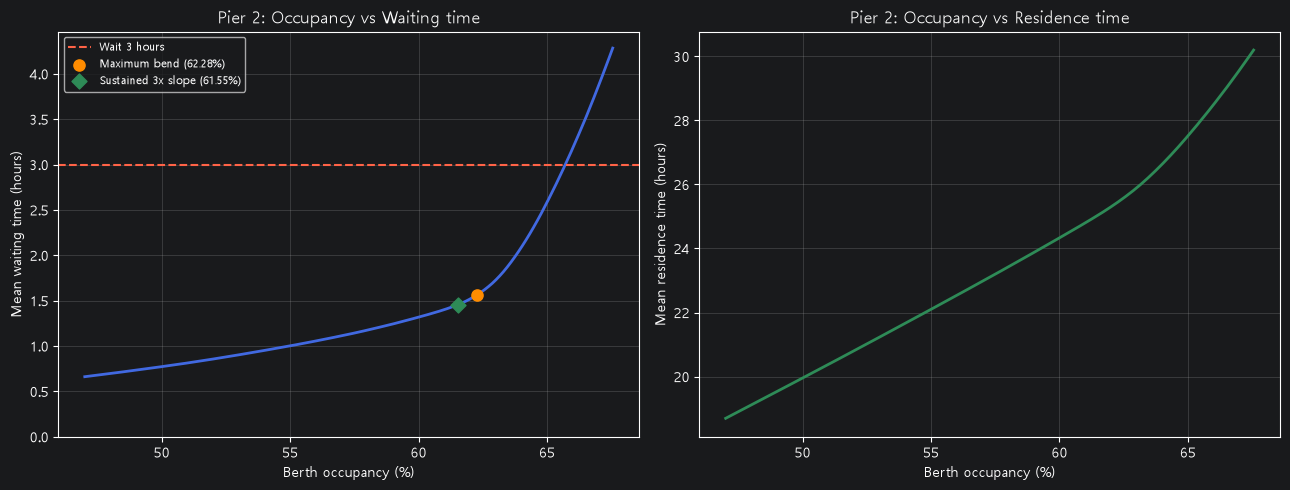

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(results2['점유율'], results2['평균대기시간'],
             color='royalblue', linewidth=2)
axes[0].axhline(3, color='tomato', linestyle='--', label='Wait 3 hours')
axes[0].scatter(x[bend_idx], y[bend_idx], color='darkorange', s=65,
                label=f'Maximum bend ({x[bend_idx]:.2f}%)', zorder=5)
if onset_idx is not None:
    axes[0].scatter(x[onset_idx], y[onset_idx], marker='D', color='seagreen',
                    s=58, label=f'Sustained 3x slope ({x[onset_idx]:.2f}%)', zorder=6)
axes[0].set_title('Pier 2: Occupancy vs Waiting time')
axes[0].set_xlabel('Berth occupancy (%)')
axes[0].set_ylabel('Mean waiting time (hours)')
axes[0].set_ylim(bottom=0)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(results2['점유율'], results2['평균재항시간'],
             color='seagreen', linewidth=2)
axes[1].set_title('Pier 2: Occupancy vs Residence time')
axes[1].set_xlabel('Berth occupancy (%)')
axes[1].set_ylabel('Mean residence time (hours)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---

# 3부두 분석

## 3-1. 파일 읽기 및 원본 확인

이 부두의 터미널 CSV와 `record.csv`를 **직접 읽습니다.** 이전 부두에서 가공한 `ships`나 별도 결과 CSV를 이용하지 않습니다.

In [22]:
port3 = read_csv('port3.csv')
record3 = read_csv('record.csv')

print('port3:', port3.shape, 'record:', record3.shape)
display(port3.head())
display(record3.head())

port3: (3773, 7) record: (19989, 13)


,선석,선박명,접안(예정)일시,출항(예정)일시,양하,적하,Shift
0,1,SEABREEZE,2021-12-31 8:00,2022-01-01 0:00,701,658,70
1,3,JEBEL ALI,2021-12-31 19:00,2022-01-02 15:00,3415,2129,222
2,2,NYK ISABEL,2021-12-31 22:00,2022-01-01 21:00,1273,1063,0
3,1,SEASPAN THAMES,2022-01-01 2:00,2022-01-02 18:00,1015,2080,28
4,4,EVER SUPERB,2022-01-02 17:00,2022-01-03 16:00,778,1038,8


,호출부호,선명,입항횟수,총톤수,입항일시,출항일시,CIQ수속일자,수리일시,MRN 번호,계선장소,차항지,전출항지,재항시간
0,3FRF8,SONG YUN HE,2022.0,"16,737",2022-01-01 00:48:00,2022-01-03 01:52:00,2022-01-03 1:52,2022-01-03 15:58,22COHES152E,신항 5부두 3선석,QINGDAO,광양,49.066667
1,VRNA9,SEASPAN THAMES,2022.0,"112,967",2022-01-01 02:00:00,2022-01-02 17:43:00,2022-01-02 17:43,2022-01-03 11:18,22HLCU4202E,신항 3부두 4선석,VANCOUVER,SHANGHAI,39.716667
2,VRRP8,CMA CGM MUMBAI,2022.0,"112,967",2022-01-01 03:00:00,2022-01-02 04:06:00,2022-01-02 4:00,2022-01-03 11:22,22CMAL0030E,신항 5부두 2선석,MANZANILLO,SHANGHAI,25.100000
3,D5TL4,MSC JEWEL,2022.0,"140,976",2022-01-01 03:22:00,2022-01-03 05:00:00,2022-01-03 5:00,2022-01-03 11:19,22MSCU0004E,신항 1부두 3선석,MANZANILLO,HONG KONG,49.633333
4,A8YT7,MALIAKOS,2022.0,"41,391",2022-01-01 03:35:00,2022-01-01 16:45:00,2022-01-01 16:00,2022-01-03 11:07,22SMLME016E,신항 2부두 1선석,VANCOUVER,SHANGHAI,13.166667


## 3-2. 시각 변환과 선석사용시간 계산

접안시각과 터미널의 출항(예정)시각 차이를 **선석사용시간**으로 계산합니다. PORTMIS의 입항·출항시각도 `datetime`으로 변환합니다.

In [23]:
port = port3.copy()
rec = record3.copy()

port['접안시각'] = pd.to_datetime(port['접안(예정)일시'], format='mixed', errors='coerce')
port['선석종료시각'] = pd.to_datetime(port['출항(예정)일시'], format='mixed', errors='coerce')
rec['입항시각'] = pd.to_datetime(rec['입항일시'], format='mixed', errors='coerce')
rec['출항시각'] = pd.to_datetime(rec['출항일시'], format='mixed', errors='coerce')

port['선석사용시간'] = (
    port['선석종료시각'] - port['접안시각']
).dt.total_seconds() / 3600

print('선석사용시간 확인')
display(port[['선석', '접안시각', '선석종료시각', '선석사용시간']].head())

선석사용시간 확인


,선석,접안시각,선석종료시각,선석사용시간
0,1,2021-12-31 08:00:00,2022-01-01 00:00:00,16.0
1,3,2021-12-31 19:00:00,2022-01-02 15:00:00,44.0
2,2,2021-12-31 22:00:00,2022-01-01 21:00:00,23.0
3,1,2022-01-01 02:00:00,2022-01-02 18:00:00,40.0
4,4,2022-01-02 17:00:00,2022-01-03 16:00:00,23.0


## 3-3. 선박명과 선석번호 정리

- 선박명에서 공백을 없애고 대문자로 변환합니다.
- 터미널 선석을 PORTMIS의 선석번호로 맞춥니다.
- **3부두:** 사용자가 정한 역순 대응을 적용합니다. 터미널 1→PORTMIS 4, 2→3, 3→2, 4→1. 이 대응은 가정입니다.


In [24]:
# 이번 부두 PORTMIS 기록만 선택
rec = rec[
    rec['계선장소'].astype('string').str.match(
        r'^신항 3부두 \d+선석$', na=False
    )
].copy()

port['연결선명'] = (
    port['선박명'].astype('string').str.upper().str.replace(r'\s+', '', regex=True)
)
rec['연결선명'] = (
    rec['선명'].astype('string').str.upper().str.replace(r'\s+', '', regex=True)
)

# 'T1' 형식과 '1' 형식을 모두 처리 (T 문자가 없어도 됨)
port['원본선석번호'] = pd.to_numeric(
    port['선석'].astype('string').str.extract(r'(\d+)')[0], errors='coerce'
)
port['선석번호'] = port['원본선석번호'].map({1: 4, 2: 3, 3: 2, 4: 1})
rec['선석번호'] = pd.to_numeric(
    rec['계선장소'].astype('string').str.extract(r'(\d+)선석')[0], errors='coerce'
)

# 숫자로 통일한 다음 문자열로 맞춤 (예: 1.0 → '1')
port['선석번호'] = port['선석번호'].astype('Int64').astype('string')
rec['선석번호'] = rec['선석번호'].astype('Int64').astype('string')
rec['기록번호'] = range(len(rec))

print('터미널 선석번호 대응')
display(port[['선석', '원본선석번호', '선석번호']].drop_duplicates().sort_values('선석번호'))
print('PORTMIS 선석번호별 건수')
display(rec['선석번호'].value_counts().sort_index())

터미널 선석번호 대응


,선석,원본선석번호,선석번호
4,4,4,1
1,3,3,2
2,2,2,3
0,1,1,4


PORTMIS 선석번호별 건수


선석번호
1     739
2     459
3    1275
4    1205
Name: count, dtype: int64[pyarrow]

## 3-4. `merge_asof()`로 두 자료 연결

선박명·선석번호가 같고 **출항시각 차이가 24시간 이내인 기록 중 가장 가까운 것**을 연결합니다. 연결 실패한 행과 중복 행 수를 확인합니다.

In [25]:
port_before = len(port)
port = port.dropna(subset=['선석번호', '연결선명', '접안시각', '선석종료시각']).copy()
rec = rec.dropna(subset=['선석번호', '연결선명', '입항시각', '출항시각']).copy()

ships = pd.merge_asof(
    port.sort_values('선석종료시각'),
    rec[['연결선명', '선석번호', '입항시각', '출항시각', '기록번호']].sort_values('출항시각'),
    left_on='선석종료시각',
    right_on='출항시각',
    by=['연결선명', '선석번호'],
    direction='nearest',
    tolerance=pd.Timedelta(hours=24)
)

unmatched = ships['기록번호'].isna().sum()
ships = ships.dropna(subset=['기록번호']).copy()
ships['출항시각차이'] = (ships['선석종료시각'] - ships['출항시각']).abs()
ships = ships.sort_values('출항시각차이')
duplicated = ships['기록번호'].duplicated().sum()
ships = ships.drop_duplicates('기록번호').copy()

print('시각/이름/선석 누락으로 제외:', port_before - len(port))
print('연결 실패:', unmatched)
print('동일 기록번호 중복 제외:', duplicated)
print('연결 및 중복 제거 후:', len(ships))
display(ships[['선석번호', '입항시각', '접안시각', '선석종료시각', '출항시각']].head())

시각/이름/선석 누락으로 제외: 0
연결 실패: 594
동일 기록번호 중복 제외: 0
연결 및 중복 제거 후: 3179


,선석번호,입항시각,접안시각,선석종료시각,출항시각
3169,4,2025-06-11 07:34:00,2025-06-11 07:00:00,2025-06-12 03:00:00,2025-06-12 03:00:00
750,3,2022-10-24 07:50:00,2022-10-24 08:00:00,2022-10-24 23:46:00,2022-10-24 23:46:00
745,2,2022-10-21 13:55:00,2022-10-21 14:00:00,2022-10-22 18:00:00,2022-10-22 18:00:00
738,1,2022-10-19 03:05:00,2022-10-19 03:00:00,2022-10-20 09:00:00,2022-10-20 09:00:00
2449,3,2024-08-19 02:20:00,2024-08-19 02:00:00,2024-08-19 18:00:00,2024-08-19 18:00:00


## 3-5. 시간 조건 확인 및 분석 기간 선택

`접안전시간 ≥ 0`, `선석사용시간 > 0`, `재항시간 > 0` 조건을 모두 만족해야 사용합니다. 이번에는 **제외 데이터도 별도로 확인**합니다.

In [26]:
ships['접안전시간'] = (
    ships['접안시각'] - ships['입항시각']
).dt.total_seconds() / 3600
ships['재항시간'] = (
    ships['출항시각'] - ships['입항시각']
).dt.total_seconds() / 3600

bad = (
    (ships['접안전시간'] < 0)
    | (ships['선석사용시간'] <= 0)
    | (ships['재항시간'] <= 0)
    | ships[['접안전시간', '선석사용시간', '재항시간']].isna().any(axis=1)
)
out_ships3 = ships[bad].copy()
cp_ships3 = ships[~bad].copy()

# 2022~2025년 입항 기록만 선택
sim_data3 = cp_ships3[
    (cp_ships3['입항시각'] >= period_start)
    & (cp_ships3['입항시각'] < period_end)
].sort_values('입항시각').copy()

print('시간 조건 제외:', len(out_ships3))
print('시간 조건 통과:', len(cp_ships3))
print('2022~2025년 최종 분석:', len(sim_data3))
print('최종 분석 선석:', sorted(sim_data3['선석번호'].dropna().unique().tolist()))
display(sim_data3[['입항시각', '접안시각', '선석번호', '선석사용시간', '접안전시간', '재항시간']].head())

시간 조건 제외: 1220
시간 조건 통과: 1959
2022~2025년 최종 분석: 1959
최종 분석 선석: ['1', '2', '3', '4']


,입항시각,접안시각,선석번호,선석사용시간,접안전시간,재항시간
3,2022-01-01 02:00:00,2022-01-01 02:00:00,4,40.0,0.000000,39.716667
5,2022-01-02 19:40:00,2022-01-02 20:00:00,4,34.0,0.333333,34.333333
10,2022-01-04 09:55:00,2022-01-04 10:00:00,4,36.0,0.083333,36.216667
8,2022-01-04 09:55:00,2022-01-04 10:00:00,2,9.0,0.083333,8.833333
9,2022-01-04 10:25:00,2022-01-04 11:00:00,3,24.0,0.583333,24.500000


## 3-6. 시뮬레이션 입력 준비

입항시각을 분석 시작부터 경과한 시간으로 바꾸고, 출항 추가시간을 계산합니다. 각 선석에 배가 차례대로 도착했을 때의 대기시간을 계산합니다.

In [27]:
sim_data3['입항경과시간'] = (
    sim_data3['입항시각'] - period_start
).dt.total_seconds() / 3600
sim_data3['출항추가시간'] = (
    sim_data3['출항시각'] - sim_data3['선석종료시각']
).dt.total_seconds().div(3600).clip(lower=0)

배정자료 = list(
    sim_data3[
        ['입항경과시간', '선석번호', '선석사용시간', '출항추가시간']
    ].itertuples(index=False, name=None)
)

# 연결에 성공한 선석만 시뮬레이션에 사용
선석목록 = sorted(int(v) for v in sim_data3['선석번호'].unique())
선석수 = len(선석목록)
assert 선석수 > 0 and len(배정자료) > 0, '분석에 사용할 선박/선석이 없습니다.'

# 원래 노트북과 같은 대기행렬 계산
def simulate(scale):
    free = {berth: 0.0 for berth in 선석목록}
    waits = []
    residences = []
    occupied = 0.0

    for arrival, berth, service, exit_time in 배정자료:
        berth = int(berth)
        work = service * scale
        start = max(arrival, free[berth])
        finish = start + work
        free[berth] = finish

        waits.append(start - arrival)
        residences.append(finish + exit_time - arrival)
        occupied += max(0, min(finish, period_hours) - max(start, 0))

    return {
        '사용시간배율': scale,
        '점유율': occupied / (선석수 * period_hours) * 100,
        '평균대기시간': sum(waits) / len(waits),
        '평균재항시간': sum(residences) / len(residences)
    }

baseline3 = simulate(1.0)
print('사용시간 100%의 결과')
display(pd.DataFrame([baseline3]).round(2))

사용시간 100%의 결과


,사용시간배율,점유율,평균대기시간,평균재항시간
0,1.0,25.21,1.12,19.24


## 3-7. 80~115% 시나리오 계산

수업자료처럼 **0.0025(0.25%p)** 간격으로 141번 계산합니다. 다른 CSV에서 결과를 불러오지 않습니다.

In [28]:
scales = [0.80 + i * 0.0025 for i in range(141)]
results3 = pd.DataFrame([simulate(scale) for scale in scales])

print('시뮬레이션 건수:', len(results3))
display(results3.head())
display(results3.tail())

시뮬레이션 건수: 141


,사용시간배율,점유율,평균대기시간,평균재항시간
0,0.8000,20.169224,0.621921,15.131899
1,0.8025,20.232253,0.626966,15.182069
2,0.8050,20.295282,0.632019,15.232249
3,0.8075,20.358310,0.637088,15.282443
4,0.8100,20.421339,0.642193,15.332675


,사용시간배율,점유율,평균대기시간,평균재항시간
136,1.1400,28.741144,1.949875,22.596980
137,1.1425,28.804173,1.977519,22.669750
138,1.1450,28.867202,2.005447,22.742804
139,1.1475,28.930231,2.033743,22.816226
140,1.1500,28.993259,2.062508,22.890117


## 3-8. 최대 굴곡점과 초기 기울기 3배 지속 시작점

**최대 굴곡점:** 정규화한 곡선과 양 끝점을 이은 직선 사이의 최대 간격.  
**3배 지속 시작점:** 초기 기울기(첫 40구간 중앙값)의 3배 이상인 기울기가 연속 5구간 유지되는 첫 위치.  
두 기준을 계산한 뒤, 최초 노트북의 **평균 대기 3시간 도달점**도 함께 계산합니다.

In [29]:
x = results3['점유율'].to_numpy()
y = results3['평균대기시간'].to_numpy()

# 1) 곡선의 최대 굴곡점: 직선에서 가장 크게 벌어진 지점
x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (y - y.min()) / (y.max() - y.min())
distance = x_norm - y_norm
candidate = np.arange(max(2, int(len(x) * 0.1)), min(len(x)-2, int(len(x) * 0.9)))
bend_idx = int(candidate[np.argmax(distance[candidate])])

# 2) 이웃한 시나리오의 기울기를 계산하고 5구간 이동중앙값 사용
slope = np.diff(y) / np.diff(x)
smooth_slope = pd.Series(slope).rolling(5, center=True, min_periods=1).median().to_numpy()
initial_slope = float(np.median(smooth_slope[:40]))

onset_idx = None
for i in range(40, len(smooth_slope)-4):
    if (smooth_slope[i:i+5] >= initial_slope * 3).all():
        onset_idx = i
        break

# 3) 평균 대기시간이 3시간에 도달하는 지점 (원본 노트북의 보간 방식)
below = results3[results3['평균대기시간'] < 3]
above = results3[results3['평균대기시간'] >= 3]
occupancy_at_3h = np.nan
if len(below) > 0 and len(above) > 0:
    p1 = below.iloc[-1]
    p2 = above.iloc[0]
    if p1['사용시간배율'] < p2['사용시간배율']:
        ratio = (3 - p1['평균대기시간']) / (p2['평균대기시간'] - p1['평균대기시간'])
        occupancy_at_3h = p1['점유율'] + ratio * (p2['점유율'] - p1['점유율'])

print(f'최대 굴곡점: {x[bend_idx]:.2f}% / 대기 {y[bend_idx]:.2f}시간')
if onset_idx is not None:
    print(f'기울기 3배 지속 시작: {x[onset_idx]:.2f}% / 대기 {y[onset_idx]:.2f}시간')
else:
    print('기울기 3배 지속 시작: 범위 안에서 찾지 못함')
print('평균 대기 3시간 도달점:', round(occupancy_at_3h, 2) if pd.notna(occupancy_at_3h) else '범위 내 미도달')

summary3 = {
    '부두': '3부두',
    '최종 분석 건수': len(sim_data3),
    '기본 점유율': baseline3['점유율'],
    '최대 굴곡점': x[bend_idx],
    '기울기 3배 시작점': x[onset_idx] if onset_idx is not None else np.nan,
    '대기 3시간 도달점': occupancy_at_3h
}

최대 굴곡점: 26.60% / 대기 1.30시간
기울기 3배 지속 시작: 27.35% / 대기 1.46시간
평균 대기 3시간 도달점: 범위 내 미도달


## 3-9. 그래프 출력

최초 `EDA-kwon` 형식과 동일하게 **좌: 대기시간 / 우: 재항시간**으로 그립니다. 왼쪽에만 두 분석 지점과 3시간 점선을 추가합니다. **일반 선형 축**입니다.

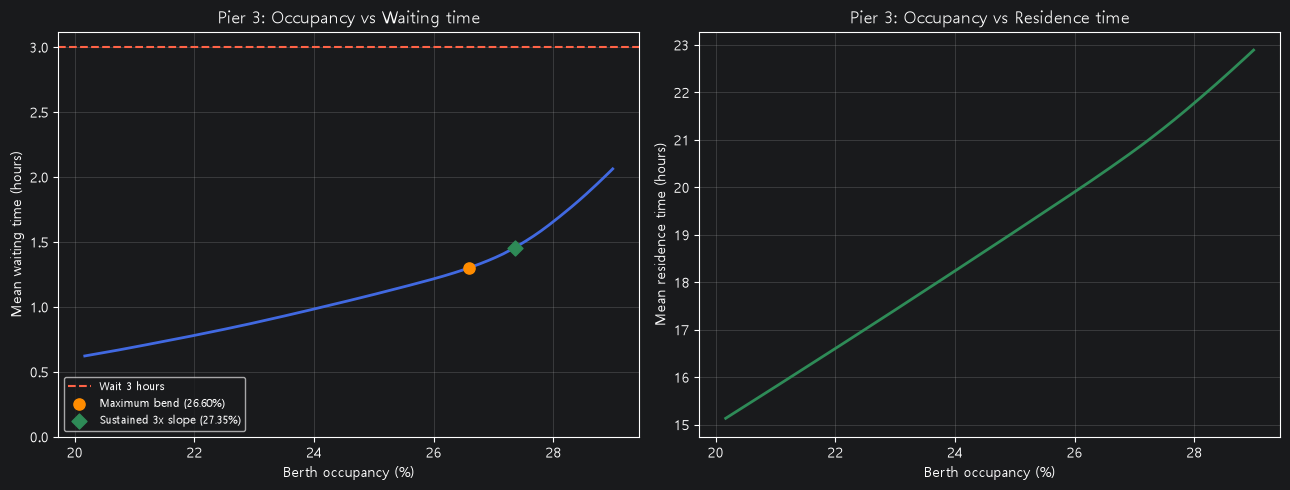

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(results3['점유율'], results3['평균대기시간'],
             color='royalblue', linewidth=2)
axes[0].axhline(3, color='tomato', linestyle='--', label='Wait 3 hours')
axes[0].scatter(x[bend_idx], y[bend_idx], color='darkorange', s=65,
                label=f'Maximum bend ({x[bend_idx]:.2f}%)', zorder=5)
if onset_idx is not None:
    axes[0].scatter(x[onset_idx], y[onset_idx], marker='D', color='seagreen',
                    s=58, label=f'Sustained 3x slope ({x[onset_idx]:.2f}%)', zorder=6)
axes[0].set_title('Pier 3: Occupancy vs Waiting time')
axes[0].set_xlabel('Berth occupancy (%)')
axes[0].set_ylabel('Mean waiting time (hours)')
axes[0].set_ylim(bottom=0)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(results3['점유율'], results3['평균재항시간'],
             color='seagreen', linewidth=2)
axes[1].set_title('Pier 3: Occupancy vs Residence time')
axes[1].set_xlabel('Berth occupancy (%)')
axes[1].set_ylabel('Mean residence time (hours)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---

# 4부두 분석

## 4-1. 파일 읽기 및 원본 확인

이 부두의 터미널 CSV와 `record.csv`를 **직접 읽습니다.** 이전 부두에서 가공한 `ships`나 별도 결과 CSV를 이용하지 않습니다.

In [31]:
port4 = read_csv('port4.csv')
record4 = read_csv('record.csv')

print('port4:', port4.shape, 'record:', record4.shape)
display(port4.head())
display(record4.head())

port4: (5774, 7) record: (19989, 13)


,선석,선명,접안(예정)일시,출항(예정)일시,양하,적하,Shift
0,1,HYUNDAI BUSAN,2019-12-31 11:12,2020-01-01 4:00,641,405,120
1,2,HMM VANCOUVER,2019-12-31 12:00,2020-01-01 11:00,1421,837,322
2,1,ALS CERES,2020-01-01 6:00,2020-01-01 20:00,656,405,0
3,3,KOWLLON BAY,2020-01-01 7:00,2020-01-01 18:00,660,235,0
4,1,NORTH BRIDGE,2020-01-02 12:00,2020-01-03 3:00,340,953,0


,호출부호,선명,입항횟수,총톤수,입항일시,출항일시,CIQ수속일자,수리일시,MRN 번호,계선장소,차항지,전출항지,재항시간
0,3FRF8,SONG YUN HE,2022.0,"16,737",2022-01-01 00:48:00,2022-01-03 01:52:00,2022-01-03 1:52,2022-01-03 15:58,22COHES152E,신항 5부두 3선석,QINGDAO,광양,49.066667
1,VRNA9,SEASPAN THAMES,2022.0,"112,967",2022-01-01 02:00:00,2022-01-02 17:43:00,2022-01-02 17:43,2022-01-03 11:18,22HLCU4202E,신항 3부두 4선석,VANCOUVER,SHANGHAI,39.716667
2,VRRP8,CMA CGM MUMBAI,2022.0,"112,967",2022-01-01 03:00:00,2022-01-02 04:06:00,2022-01-02 4:00,2022-01-03 11:22,22CMAL0030E,신항 5부두 2선석,MANZANILLO,SHANGHAI,25.100000
3,D5TL4,MSC JEWEL,2022.0,"140,976",2022-01-01 03:22:00,2022-01-03 05:00:00,2022-01-03 5:00,2022-01-03 11:19,22MSCU0004E,신항 1부두 3선석,MANZANILLO,HONG KONG,49.633333
4,A8YT7,MALIAKOS,2022.0,"41,391",2022-01-01 03:35:00,2022-01-01 16:45:00,2022-01-01 16:00,2022-01-03 11:07,22SMLME016E,신항 2부두 1선석,VANCOUVER,SHANGHAI,13.166667


## 4-2. 시각 변환과 선석사용시간 계산

접안시각과 터미널의 출항(예정)시각 차이를 **선석사용시간**으로 계산합니다. PORTMIS의 입항·출항시각도 `datetime`으로 변환합니다.

In [32]:
port = port4.copy()
rec = record4.copy()

port['접안시각'] = pd.to_datetime(port['접안(예정)일시'], format='mixed', errors='coerce')
port['선석종료시각'] = pd.to_datetime(port['출항(예정)일시'], format='mixed', errors='coerce')
rec['입항시각'] = pd.to_datetime(rec['입항일시'], format='mixed', errors='coerce')
rec['출항시각'] = pd.to_datetime(rec['출항일시'], format='mixed', errors='coerce')

port['선석사용시간'] = (
    port['선석종료시각'] - port['접안시각']
).dt.total_seconds() / 3600

print('선석사용시간 확인')
display(port[['선석', '접안시각', '선석종료시각', '선석사용시간']].head())

선석사용시간 확인


,선석,접안시각,선석종료시각,선석사용시간
0,1,2019-12-31 11:12:00,2020-01-01 04:00:00,16.8
1,2,2019-12-31 12:00:00,2020-01-01 11:00:00,23.0
2,1,2020-01-01 06:00:00,2020-01-01 20:00:00,14.0
3,3,2020-01-01 07:00:00,2020-01-01 18:00:00,11.0
4,1,2020-01-02 12:00:00,2020-01-03 03:00:00,15.0


## 4-3. 선박명과 선석번호 정리

- 선박명에서 공백을 없애고 대문자로 변환합니다.
- 터미널 선석을 PORTMIS의 선석번호로 맞춥니다.


In [33]:
# 이번 부두 PORTMIS 기록만 선택
rec = rec[
    rec['계선장소'].astype('string').str.match(
        r'^신항 4부두 \d+선석$', na=False
    )
].copy()

port['연결선명'] = (
    port['선명'].astype('string').str.upper().str.replace(r'\s+', '', regex=True)
)
rec['연결선명'] = (
    rec['선명'].astype('string').str.upper().str.replace(r'\s+', '', regex=True)
)

# 'T1' 형식과 '1' 형식을 모두 처리 (T 문자가 없어도 됨)
port['원본선석번호'] = pd.to_numeric(
    port['선석'].astype('string').str.extract(r'(\d+)')[0], errors='coerce'
)
port['선석번호'] = port['원본선석번호']
rec['선석번호'] = pd.to_numeric(
    rec['계선장소'].astype('string').str.extract(r'(\d+)선석')[0], errors='coerce'
)

# 숫자로 통일한 다음 문자열로 맞춤 (예: 1.0 → '1')
port['선석번호'] = port['선석번호'].astype('Int64').astype('string')
rec['선석번호'] = rec['선석번호'].astype('Int64').astype('string')
rec['기록번호'] = range(len(rec))

print('터미널 선석번호 대응')
display(port[['선석', '원본선석번호', '선석번호']].drop_duplicates().sort_values('선석번호'))
print('PORTMIS 선석번호별 건수')
display(rec['선석번호'].value_counts().sort_index())

터미널 선석번호 대응


,선석,원본선석번호,선석번호
0,1,1,1
1,2,2,2
3,3,3,3


PORTMIS 선석번호별 건수


선석번호
1    1119
2    1087
3    1086
4       1
Name: count, dtype: int64[pyarrow]

## 4-4. `merge_asof()`로 두 자료 연결

선박명·선석번호가 같고 **출항시각 차이가 24시간 이내인 기록 중 가장 가까운 것**을 연결합니다. 연결 실패한 행과 중복 행 수를 확인합니다.

In [34]:
port_before = len(port)
port = port.dropna(subset=['선석번호', '연결선명', '접안시각', '선석종료시각']).copy()
rec = rec.dropna(subset=['선석번호', '연결선명', '입항시각', '출항시각']).copy()

ships = pd.merge_asof(
    port.sort_values('선석종료시각'),
    rec[['연결선명', '선석번호', '입항시각', '출항시각', '기록번호']].sort_values('출항시각'),
    left_on='선석종료시각',
    right_on='출항시각',
    by=['연결선명', '선석번호'],
    direction='nearest',
    tolerance=pd.Timedelta(hours=24)
)

unmatched = ships['기록번호'].isna().sum()
ships = ships.dropna(subset=['기록번호']).copy()
ships['출항시각차이'] = (ships['선석종료시각'] - ships['출항시각']).abs()
ships = ships.sort_values('출항시각차이')
duplicated = ships['기록번호'].duplicated().sum()
ships = ships.drop_duplicates('기록번호').copy()

print('시각/이름/선석 누락으로 제외:', port_before - len(port))
print('연결 실패:', unmatched)
print('동일 기록번호 중복 제외:', duplicated)
print('연결 및 중복 제거 후:', len(ships))
display(ships[['선석번호', '입항시각', '접안시각', '선석종료시각', '출항시각']].head())

시각/이름/선석 누락으로 제외: 0
연결 실패: 2958
동일 기록번호 중복 제외: 2
연결 및 중복 제거 후: 2814


,선석번호,입항시각,접안시각,선석종료시각,출항시각
3712,2,2024-02-24 11:55:00,2024-02-24 12:12:00,2024-02-25 02:00:00,2024-02-25 02:00:00
5165,1,2025-10-25 10:00:00,2025-10-25 10:00:00,2025-10-26 01:00:00,2025-10-26 01:00:00
5166,3,2025-10-25 18:40:00,2025-10-25 19:06:00,2025-10-26 18:00:00,2025-10-26 18:00:00
3043,2,2023-05-30 01:52:00,2023-05-30 02:00:00,2023-05-31 08:00:00,2023-05-31 08:00:00
5168,1,2025-10-26 10:50:00,2025-10-26 11:00:00,2025-10-27 03:00:00,2025-10-27 03:00:00


## 4-5. 시간 조건 확인 및 분석 기간 선택

`접안전시간 ≥ 0`, `선석사용시간 > 0`, `재항시간 > 0` 조건을 모두 만족해야 사용합니다. 이번에는 **제외 데이터도 별도로 확인**합니다.

In [35]:
ships['접안전시간'] = (
    ships['접안시각'] - ships['입항시각']
).dt.total_seconds() / 3600
ships['재항시간'] = (
    ships['출항시각'] - ships['입항시각']
).dt.total_seconds() / 3600

bad = (
    (ships['접안전시간'] < 0)
    | (ships['선석사용시간'] <= 0)
    | (ships['재항시간'] <= 0)
    | ships[['접안전시간', '선석사용시간', '재항시간']].isna().any(axis=1)
)
out_ships4 = ships[bad].copy()
cp_ships4 = ships[~bad].copy()

# 2022~2025년 입항 기록만 선택
sim_data4 = cp_ships4[
    (cp_ships4['입항시각'] >= period_start)
    & (cp_ships4['입항시각'] < period_end)
].sort_values('입항시각').copy()

print('시간 조건 제외:', len(out_ships4))
print('시간 조건 통과:', len(cp_ships4))
print('2022~2025년 최종 분석:', len(sim_data4))
print('최종 분석 선석:', sorted(sim_data4['선석번호'].dropna().unique().tolist()))
display(sim_data4[['입항시각', '접안시각', '선석번호', '선석사용시간', '접안전시간', '재항시간']].head())

시간 조건 제외: 303
시간 조건 통과: 2511
2022~2025년 최종 분석: 2511
최종 분석 선석: ['1', '2', '3']


,입항시각,접안시각,선석번호,선석사용시간,접안전시간,재항시간
1914,2022-01-01 03:55:00,2022-01-01 04:00:00,1,10.0,0.083333,11.166667
1916,2022-01-01 10:00:00,2022-01-01 10:00:00,2,16.1,0.000000,16.333333
1917,2022-01-01 16:35:00,2022-01-01 17:00:00,1,13.0,0.416667,13.416667
1918,2022-01-02 20:05:00,2022-01-02 20:18:00,2,22.7,0.216667,22.866667
1920,2022-01-03 16:15:00,2022-01-03 16:54:00,3,16.1,0.650000,17.083333


## 4-6. 시뮬레이션 입력 준비

입항시각을 분석 시작부터 경과한 시간으로 바꾸고, 출항 추가시간을 계산합니다. 각 선석에 배가 차례대로 도착했을 때의 대기시간을 계산합니다.

In [36]:
sim_data4['입항경과시간'] = (
    sim_data4['입항시각'] - period_start
).dt.total_seconds() / 3600
sim_data4['출항추가시간'] = (
    sim_data4['출항시각'] - sim_data4['선석종료시각']
).dt.total_seconds().div(3600).clip(lower=0)

배정자료 = list(
    sim_data4[
        ['입항경과시간', '선석번호', '선석사용시간', '출항추가시간']
    ].itertuples(index=False, name=None)
)

# 연결에 성공한 선석만 시뮬레이션에 사용
선석목록 = sorted(int(v) for v in sim_data4['선석번호'].unique())
선석수 = len(선석목록)
assert 선석수 > 0 and len(배정자료) > 0, '분석에 사용할 선박/선석이 없습니다.'

# 원래 노트북과 같은 대기행렬 계산
def simulate(scale):
    free = {berth: 0.0 for berth in 선석목록}
    waits = []
    residences = []
    occupied = 0.0

    for arrival, berth, service, exit_time in 배정자료:
        berth = int(berth)
        work = service * scale
        start = max(arrival, free[berth])
        finish = start + work
        free[berth] = finish

        waits.append(start - arrival)
        residences.append(finish + exit_time - arrival)
        occupied += max(0, min(finish, period_hours) - max(start, 0))

    return {
        '사용시간배율': scale,
        '점유율': occupied / (선석수 * period_hours) * 100,
        '평균대기시간': sum(waits) / len(waits),
        '평균재항시간': sum(residences) / len(residences)
    }

baseline4 = simulate(1.0)
print('사용시간 100%의 결과')
display(pd.DataFrame([baseline4]).round(2))

사용시간 100%의 결과


,사용시간배율,점유율,평균대기시간,평균재항시간
0,1.0,50.81,1.03,22.81


## 4-7. 80~115% 시나리오 계산

수업자료처럼 **0.0025(0.25%p)** 간격으로 141번 계산합니다. 다른 CSV에서 결과를 불러오지 않습니다.

In [37]:
scales = [0.80 + i * 0.0025 for i in range(141)]
results4 = pd.DataFrame([simulate(scale) for scale in scales])

print('시뮬레이션 건수:', len(results4))
display(results4.head())
display(results4.tail())

시뮬레이션 건수: 141


,사용시간배율,점유율,평균대기시간,평균재항시간
0,0.8000,40.653202,0.595795,18.110496
1,0.8025,40.780192,0.600164,18.168140
2,0.8050,40.907181,0.604549,18.225798
3,0.8075,41.034170,0.608966,18.283489
4,0.8100,41.161159,0.613383,18.341179


,사용시간배율,점유율,평균대기시간,평균재항시간
136,1.1400,57.918131,2.282411,27.042322
137,1.1425,58.044731,2.334979,27.148163
138,1.1450,58.171297,2.389211,27.255669
139,1.1475,58.297813,2.443788,27.363520
140,1.1500,58.424294,2.499005,27.472010


## 4-8. 최대 굴곡점과 초기 기울기 3배 지속 시작점

**최대 굴곡점:** 정규화한 곡선과 양 끝점을 이은 직선 사이의 최대 간격.  
**3배 지속 시작점:** 초기 기울기(첫 40구간 중앙값)의 3배 이상인 기울기가 연속 5구간 유지되는 첫 위치.  
두 기준을 계산한 뒤, 최초 노트북의 **평균 대기 3시간 도달점**도 함께 계산합니다.

In [38]:
x = results4['점유율'].to_numpy()
y = results4['평균대기시간'].to_numpy()

# 1) 곡선의 최대 굴곡점: 직선에서 가장 크게 벌어진 지점
x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (y - y.min()) / (y.max() - y.min())
distance = x_norm - y_norm
candidate = np.arange(max(2, int(len(x) * 0.1)), min(len(x)-2, int(len(x) * 0.9)))
bend_idx = int(candidate[np.argmax(distance[candidate])])

# 2) 이웃한 시나리오의 기울기를 계산하고 5구간 이동중앙값 사용
slope = np.diff(y) / np.diff(x)
smooth_slope = pd.Series(slope).rolling(5, center=True, min_periods=1).median().to_numpy()
initial_slope = float(np.median(smooth_slope[:40]))

onset_idx = None
for i in range(40, len(smooth_slope)-4):
    if (smooth_slope[i:i+5] >= initial_slope * 3).all():
        onset_idx = i
        break

# 3) 평균 대기시간이 3시간에 도달하는 지점 (원본 노트북의 보간 방식)
below = results4[results4['평균대기시간'] < 3]
above = results4[results4['평균대기시간'] >= 3]
occupancy_at_3h = np.nan
if len(below) > 0 and len(above) > 0:
    p1 = below.iloc[-1]
    p2 = above.iloc[0]
    if p1['사용시간배율'] < p2['사용시간배율']:
        ratio = (3 - p1['평균대기시간']) / (p2['평균대기시간'] - p1['평균대기시간'])
        occupancy_at_3h = p1['점유율'] + ratio * (p2['점유율'] - p1['점유율'])

print(f'최대 굴곡점: {x[bend_idx]:.2f}% / 대기 {y[bend_idx]:.2f}시간')
if onset_idx is not None:
    print(f'기울기 3배 지속 시작: {x[onset_idx]:.2f}% / 대기 {y[onset_idx]:.2f}시간')
else:
    print('기울기 3배 지속 시작: 범위 안에서 찾지 못함')
print('평균 대기 3시간 도달점:', round(occupancy_at_3h, 2) if pd.notna(occupancy_at_3h) else '범위 내 미도달')

summary4 = {
    '부두': '4부두',
    '최종 분석 건수': len(sim_data4),
    '기본 점유율': baseline4['점유율'],
    '최대 굴곡점': x[bend_idx],
    '기울기 3배 시작점': x[onset_idx] if onset_idx is not None else np.nan,
    '대기 3시간 도달점': occupancy_at_3h
}

최대 굴곡점: 53.86% / 대기 1.22시간
기울기 3배 지속 시작: 54.11% / 대기 1.25시간
평균 대기 3시간 도달점: 범위 내 미도달


## 4-9. 그래프 출력

최초 `EDA-kwon` 형식과 동일하게 **좌: 대기시간 / 우: 재항시간**으로 그립니다. 왼쪽에만 두 분석 지점과 3시간 점선을 추가합니다. **일반 선형 축**입니다.

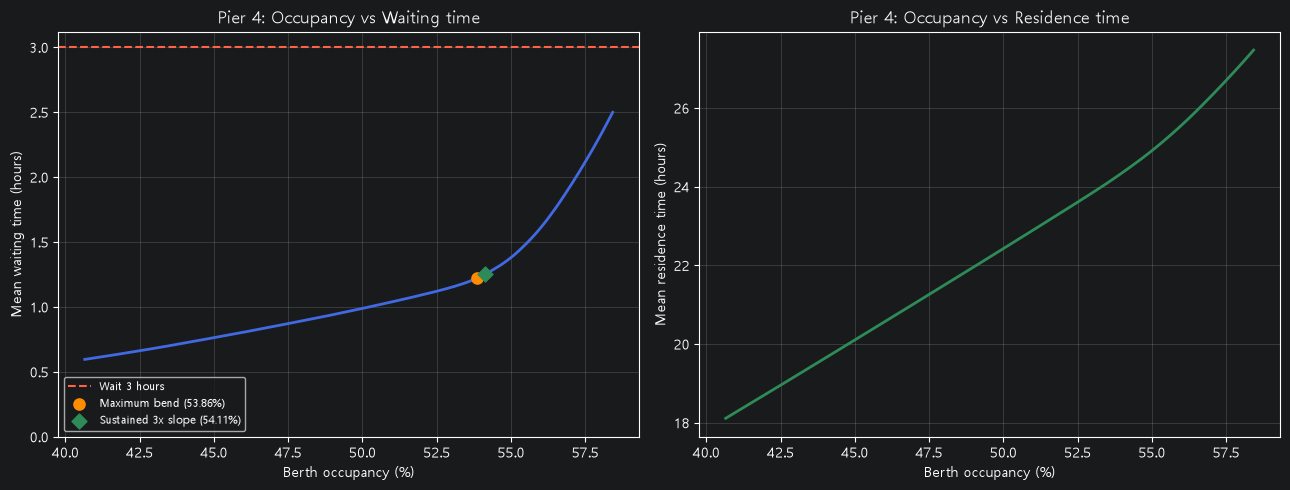

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(results4['점유율'], results4['평균대기시간'],
             color='royalblue', linewidth=2)
axes[0].axhline(3, color='tomato', linestyle='--', label='Wait 3 hours')
axes[0].scatter(x[bend_idx], y[bend_idx], color='darkorange', s=65,
                label=f'Maximum bend ({x[bend_idx]:.2f}%)', zorder=5)
if onset_idx is not None:
    axes[0].scatter(x[onset_idx], y[onset_idx], marker='D', color='seagreen',
                    s=58, label=f'Sustained 3x slope ({x[onset_idx]:.2f}%)', zorder=6)
axes[0].set_title('Pier 4: Occupancy vs Waiting time')
axes[0].set_xlabel('Berth occupancy (%)')
axes[0].set_ylabel('Mean waiting time (hours)')
axes[0].set_ylim(bottom=0)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(results4['점유율'], results4['평균재항시간'],
             color='seagreen', linewidth=2)
axes[1].set_title('Pier 4: Occupancy vs Residence time')
axes[1].set_xlabel('Berth occupancy (%)')
axes[1].set_ylabel('Mean residence time (hours)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---

# 5부두 분석

## 5-1. 파일 읽기 및 원본 확인

이 부두의 터미널 CSV와 `record.csv`를 **직접 읽습니다.** 이전 부두에서 가공한 `ships`나 별도 결과 CSV를 이용하지 않습니다.

In [40]:
port5 = read_csv('port5.csv')
record5 = read_csv('record.csv')

print('port5:', port5.shape, 'record:', record5.shape)
display(port5.head())
display(record5.head())

port5: (6156, 7) record: (19989, 13)


,선석,선명,접안(예정)일시,출항(예정)일시,양하,적하,Shift
0,4,CMA CGM LOUIS BLERIOT,2019-12-30 17:30,2020-01-01 10:12,"1,306","1,979",32
1,1,PRESIDENT EISENHOWER,2019-12-31 23:25,2020-01-01 17:15,951,8,232
2,2,QI YUN HE,2020-01-01 1:10,2020-01-01 20:50,513,557,0
3,3,EVER LEADING,2020-01-01 12:50,2020-01-02 9:50,513,647,54
4,1,PRESIDENT FD ROOSEVELT,2020-01-01 19:10,2020-01-02 15:05,100,"1,094",42


,호출부호,선명,입항횟수,총톤수,입항일시,출항일시,CIQ수속일자,수리일시,MRN 번호,계선장소,차항지,전출항지,재항시간
0,3FRF8,SONG YUN HE,2022.0,"16,737",2022-01-01 00:48:00,2022-01-03 01:52:00,2022-01-03 1:52,2022-01-03 15:58,22COHES152E,신항 5부두 3선석,QINGDAO,광양,49.066667
1,VRNA9,SEASPAN THAMES,2022.0,"112,967",2022-01-01 02:00:00,2022-01-02 17:43:00,2022-01-02 17:43,2022-01-03 11:18,22HLCU4202E,신항 3부두 4선석,VANCOUVER,SHANGHAI,39.716667
2,VRRP8,CMA CGM MUMBAI,2022.0,"112,967",2022-01-01 03:00:00,2022-01-02 04:06:00,2022-01-02 4:00,2022-01-03 11:22,22CMAL0030E,신항 5부두 2선석,MANZANILLO,SHANGHAI,25.100000
3,D5TL4,MSC JEWEL,2022.0,"140,976",2022-01-01 03:22:00,2022-01-03 05:00:00,2022-01-03 5:00,2022-01-03 11:19,22MSCU0004E,신항 1부두 3선석,MANZANILLO,HONG KONG,49.633333
4,A8YT7,MALIAKOS,2022.0,"41,391",2022-01-01 03:35:00,2022-01-01 16:45:00,2022-01-01 16:00,2022-01-03 11:07,22SMLME016E,신항 2부두 1선석,VANCOUVER,SHANGHAI,13.166667


## 5-2. 시각 변환과 선석사용시간 계산

접안시각과 터미널의 출항(예정)시각 차이를 **선석사용시간**으로 계산합니다. PORTMIS의 입항·출항시각도 `datetime`으로 변환합니다.

In [41]:
port = port5.copy()
rec = record5.copy()

port['접안시각'] = pd.to_datetime(port['접안(예정)일시'], format='mixed', errors='coerce')
port['선석종료시각'] = pd.to_datetime(port['출항(예정)일시'], format='mixed', errors='coerce')
rec['입항시각'] = pd.to_datetime(rec['입항일시'], format='mixed', errors='coerce')
rec['출항시각'] = pd.to_datetime(rec['출항일시'], format='mixed', errors='coerce')

port['선석사용시간'] = (
    port['선석종료시각'] - port['접안시각']
).dt.total_seconds() / 3600

print('선석사용시간 확인')
display(port[['선석', '접안시각', '선석종료시각', '선석사용시간']].head())

선석사용시간 확인


,선석,접안시각,선석종료시각,선석사용시간
0,4,2019-12-30 17:30:00,2020-01-01 10:12:00,40.700000
1,1,2019-12-31 23:25:00,2020-01-01 17:15:00,17.833333
2,2,2020-01-01 01:10:00,2020-01-01 20:50:00,19.666667
3,3,2020-01-01 12:50:00,2020-01-02 09:50:00,21.000000
4,1,2020-01-01 19:10:00,2020-01-02 15:05:00,19.916667


## 5-3. 선박명과 선석번호 정리

- 선박명에서 공백을 없애고 대문자로 변환합니다.
- 터미널 선석을 PORTMIS의 선석번호로 맞춥니다.


In [42]:
# 이번 부두 PORTMIS 기록만 선택
rec = rec[
    rec['계선장소'].astype('string').str.match(
        r'^신항 5부두 \d+선석$', na=False
    )
].copy()

port['연결선명'] = (
    port['선명'].astype('string').str.upper().str.replace(r'\s+', '', regex=True)
)
rec['연결선명'] = (
    rec['선명'].astype('string').str.upper().str.replace(r'\s+', '', regex=True)
)

# 'T1' 형식과 '1' 형식을 모두 처리 (T 문자가 없어도 됨)
port['원본선석번호'] = pd.to_numeric(
    port['선석'].astype('string').str.extract(r'(\d+)')[0], errors='coerce'
)
port['선석번호'] = port['원본선석번호']
rec['선석번호'] = pd.to_numeric(
    rec['계선장소'].astype('string').str.extract(r'(\d+)선석')[0], errors='coerce'
)

# 숫자로 통일한 다음 문자열로 맞춤 (예: 1.0 → '1')
port['선석번호'] = port['선석번호'].astype('Int64').astype('string')
rec['선석번호'] = rec['선석번호'].astype('Int64').astype('string')
rec['기록번호'] = range(len(rec))

print('터미널 선석번호 대응')
display(port[['선석', '원본선석번호', '선석번호']].drop_duplicates().sort_values('선석번호'))
print('PORTMIS 선석번호별 건수')
display(rec['선석번호'].value_counts().sort_index())

터미널 선석번호 대응


,선석,원본선석번호,선석번호
1,1,1,1
2,2,2,2
3,3,3,3
0,4,4,4


PORTMIS 선석번호별 건수


선석번호
1    1279
2    1033
3     326
4    1030
Name: count, dtype: int64[pyarrow]

## 5-4. `merge_asof()`로 두 자료 연결

선박명·선석번호가 같고 **출항시각 차이가 24시간 이내인 기록 중 가장 가까운 것**을 연결합니다. 연결 실패한 행과 중복 행 수를 확인합니다.

In [43]:
port_before = len(port)
port = port.dropna(subset=['선석번호', '연결선명', '접안시각', '선석종료시각']).copy()
rec = rec.dropna(subset=['선석번호', '연결선명', '입항시각', '출항시각']).copy()

ships = pd.merge_asof(
    port.sort_values('선석종료시각'),
    rec[['연결선명', '선석번호', '입항시각', '출항시각', '기록번호']].sort_values('출항시각'),
    left_on='선석종료시각',
    right_on='출항시각',
    by=['연결선명', '선석번호'],
    direction='nearest',
    tolerance=pd.Timedelta(hours=24)
)

unmatched = ships['기록번호'].isna().sum()
ships = ships.dropna(subset=['기록번호']).copy()
ships['출항시각차이'] = (ships['선석종료시각'] - ships['출항시각']).abs()
ships = ships.sort_values('출항시각차이')
duplicated = ships['기록번호'].duplicated().sum()
ships = ships.drop_duplicates('기록번호').copy()

print('시각/이름/선석 누락으로 제외:', port_before - len(port))
print('연결 실패:', unmatched)
print('동일 기록번호 중복 제외:', duplicated)
print('연결 및 중복 제거 후:', len(ships))
display(ships[['선석번호', '입항시각', '접안시각', '선석종료시각', '출항시각']].head())

시각/이름/선석 누락으로 제외: 0
연결 실패: 2760
동일 기록번호 중복 제외: 0
연결 및 중복 제거 후: 3396


,선석번호,입항시각,접안시각,선석종료시각,출항시각
1806,2,2022-01-01 03:00:00,2022-01-01 03:30:00,2022-01-02 04:06:00,2022-01-02 04:06:00
3952,1,2024-03-30 08:50:00,2024-03-30 08:54:00,2024-03-31 02:10:00,2024-03-31 02:10:00
3951,4,2024-03-29 18:55:00,2024-03-29 18:48:00,2024-03-30 11:00:00,2024-03-30 11:00:00
3950,1,2024-03-29 03:50:00,2024-03-29 04:30:00,2024-03-30 07:10:00,2024-03-30 07:10:00
3949,2,2024-03-29 05:05:00,2024-03-29 05:10:00,2024-03-29 22:55:00,2024-03-29 22:55:00


## 5-5. 시간 조건 확인 및 분석 기간 선택

`접안전시간 ≥ 0`, `선석사용시간 > 0`, `재항시간 > 0` 조건을 모두 만족해야 사용합니다. 이번에는 **제외 데이터도 별도로 확인**합니다.

In [44]:
ships['접안전시간'] = (
    ships['접안시각'] - ships['입항시각']
).dt.total_seconds() / 3600
ships['재항시간'] = (
    ships['출항시각'] - ships['입항시각']
).dt.total_seconds() / 3600

bad = (
    (ships['접안전시간'] < 0)
    | (ships['선석사용시간'] <= 0)
    | (ships['재항시간'] <= 0)
    | ships[['접안전시간', '선석사용시간', '재항시간']].isna().any(axis=1)
)
out_ships5 = ships[bad].copy()
cp_ships5 = ships[~bad].copy()

# 2022~2025년 입항 기록만 선택
sim_data5 = cp_ships5[
    (cp_ships5['입항시각'] >= period_start)
    & (cp_ships5['입항시각'] < period_end)
].sort_values('입항시각').copy()

print('시간 조건 제외:', len(out_ships5))
print('시간 조건 통과:', len(cp_ships5))
print('2022~2025년 최종 분석:', len(sim_data5))
print('최종 분석 선석:', sorted(sim_data5['선석번호'].dropna().unique().tolist()))
display(sim_data5[['입항시각', '접안시각', '선석번호', '선석사용시간', '접안전시간', '재항시간']].head())

시간 조건 제외: 47
시간 조건 통과: 3349
2022~2025년 최종 분석: 3349
최종 분석 선석: ['1', '2', '3', '4']


,입항시각,접안시각,선석번호,선석사용시간,접안전시간,재항시간
1809,2022-01-01 00:48:00,2022-01-02 17:50:00,3,8.000000,41.033333,49.066667
1806,2022-01-01 03:00:00,2022-01-01 03:30:00,2,24.600000,0.500000,25.100000
1807,2022-01-01 17:40:00,2022-01-01 18:06:00,4,21.066667,0.433333,21.500000
1811,2022-01-01 20:40:00,2022-01-01 21:06:00,1,32.900000,0.433333,33.333333
1812,2022-01-02 16:50:00,2022-01-02 17:20:00,4,19.666667,0.500000,20.083333


## 5-6. 시뮬레이션 입력 준비

입항시각을 분석 시작부터 경과한 시간으로 바꾸고, 출항 추가시간을 계산합니다. 각 선석에 배가 차례대로 도착했을 때의 대기시간을 계산합니다.

In [45]:
sim_data5['입항경과시간'] = (
    sim_data5['입항시각'] - period_start
).dt.total_seconds() / 3600
sim_data5['출항추가시간'] = (
    sim_data5['출항시각'] - sim_data5['선석종료시각']
).dt.total_seconds().div(3600).clip(lower=0)

배정자료 = list(
    sim_data5[
        ['입항경과시간', '선석번호', '선석사용시간', '출항추가시간']
    ].itertuples(index=False, name=None)
)

# 연결에 성공한 선석만 시뮬레이션에 사용
선석목록 = sorted(int(v) for v in sim_data5['선석번호'].unique())
선석수 = len(선석목록)
assert 선석수 > 0 and len(배정자료) > 0, '분석에 사용할 선박/선석이 없습니다.'

# 원래 노트북과 같은 대기행렬 계산
def simulate(scale):
    free = {berth: 0.0 for berth in 선석목록}
    waits = []
    residences = []
    occupied = 0.0

    for arrival, berth, service, exit_time in 배정자료:
        berth = int(berth)
        work = service * scale
        start = max(arrival, free[berth])
        finish = start + work
        free[berth] = finish

        waits.append(start - arrival)
        residences.append(finish + exit_time - arrival)
        occupied += max(0, min(finish, period_hours) - max(start, 0))

    return {
        '사용시간배율': scale,
        '점유율': occupied / (선석수 * period_hours) * 100,
        '평균대기시간': sum(waits) / len(waits),
        '평균재항시간': sum(residences) / len(residences)
    }

baseline5 = simulate(1.0)
print('사용시간 100%의 결과')
display(pd.DataFrame([baseline5]).round(2))

사용시간 100%의 결과


,사용시간배율,점유율,평균대기시간,평균재항시간
0,1.0,57.02,1.94,25.84


## 5-7. 80~115% 시나리오 계산

수업자료처럼 **0.0025(0.25%p)** 간격으로 141번 계산합니다. 다른 CSV에서 결과를 불러오지 않습니다.

In [46]:
scales = [0.80 + i * 0.0025 for i in range(141)]
results5 = pd.DataFrame([simulate(scale) for scale in scales])

print('시뮬레이션 건수:', len(results5))
display(results5.head())
display(results5.tail())

시뮬레이션 건수: 141


,사용시간배율,점유율,평균대기시간,평균재항시간
0,0.8000,45.615303,0.925267,20.048830
1,0.8025,45.757843,0.934069,20.117350
2,0.8050,45.900382,0.942935,20.185934
3,0.8075,46.042921,0.951895,20.254612
4,0.8100,46.185460,0.960885,20.323320


,사용시간배율,점유율,평균대기시간,평균재항시간
136,1.1400,65.000636,6.724452,33.969633
137,1.1425,65.143175,6.960287,34.265186
138,1.1450,65.285714,7.205432,34.570048
139,1.1475,65.428253,7.454741,34.879075
140,1.1500,65.570793,7.707498,35.191549


## 5-8. 최대 굴곡점과 초기 기울기 3배 지속 시작점

**최대 굴곡점:** 정규화한 곡선과 양 끝점을 이은 직선 사이의 최대 간격.  
**3배 지속 시작점:** 초기 기울기(첫 40구간 중앙값)의 3배 이상인 기울기가 연속 5구간 유지되는 첫 위치.  
두 기준을 계산한 뒤, 최초 노트북의 **평균 대기 3시간 도달점**도 함께 계산합니다.

In [47]:
x = results5['점유율'].to_numpy()
y = results5['평균대기시간'].to_numpy()

# 1) 곡선의 최대 굴곡점: 직선에서 가장 크게 벌어진 지점
x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (y - y.min()) / (y.max() - y.min())
distance = x_norm - y_norm
candidate = np.arange(max(2, int(len(x) * 0.1)), min(len(x)-2, int(len(x) * 0.9)))
bend_idx = int(candidate[np.argmax(distance[candidate])])

# 2) 이웃한 시나리오의 기울기를 계산하고 5구간 이동중앙값 사용
slope = np.diff(y) / np.diff(x)
smooth_slope = pd.Series(slope).rolling(5, center=True, min_periods=1).median().to_numpy()
initial_slope = float(np.median(smooth_slope[:40]))

onset_idx = None
for i in range(40, len(smooth_slope)-4):
    if (smooth_slope[i:i+5] >= initial_slope * 3).all():
        onset_idx = i
        break

# 3) 평균 대기시간이 3시간에 도달하는 지점 (원본 노트북의 보간 방식)
below = results5[results5['평균대기시간'] < 3]
above = results5[results5['평균대기시간'] >= 3]
occupancy_at_3h = np.nan
if len(below) > 0 and len(above) > 0:
    p1 = below.iloc[-1]
    p2 = above.iloc[0]
    if p1['사용시간배율'] < p2['사용시간배율']:
        ratio = (3 - p1['평균대기시간']) / (p2['평균대기시간'] - p1['평균대기시간'])
        occupancy_at_3h = p1['점유율'] + ratio * (p2['점유율'] - p1['점유율'])

print(f'최대 굴곡점: {x[bend_idx]:.2f}% / 대기 {y[bend_idx]:.2f}시간')
if onset_idx is not None:
    print(f'기울기 3배 지속 시작: {x[onset_idx]:.2f}% / 대기 {y[onset_idx]:.2f}시간')
else:
    print('기울기 3배 지속 시작: 범위 안에서 찾지 못함')
print('평균 대기 3시간 도달점:', round(occupancy_at_3h, 2) if pd.notna(occupancy_at_3h) else '범위 내 미도달')

summary5 = {
    '부두': '5부두',
    '최종 분석 건수': len(sim_data5),
    '기본 점유율': baseline5['점유율'],
    '최대 굴곡점': x[bend_idx],
    '기울기 3배 시작점': x[onset_idx] if onset_idx is not None else np.nan,
    '대기 3시간 도달점': occupancy_at_3h
}

최대 굴곡점: 60.72% / 대기 2.60시간
기울기 3배 지속 시작: 60.01% / 대기 2.40시간
평균 대기 3시간 도달점: 61.58


## 5-9. 그래프 출력

최초 `EDA-kwon` 형식과 동일하게 **좌: 대기시간 / 우: 재항시간**으로 그립니다. 왼쪽에만 두 분석 지점과 3시간 점선을 추가합니다. **일반 선형 축**입니다.

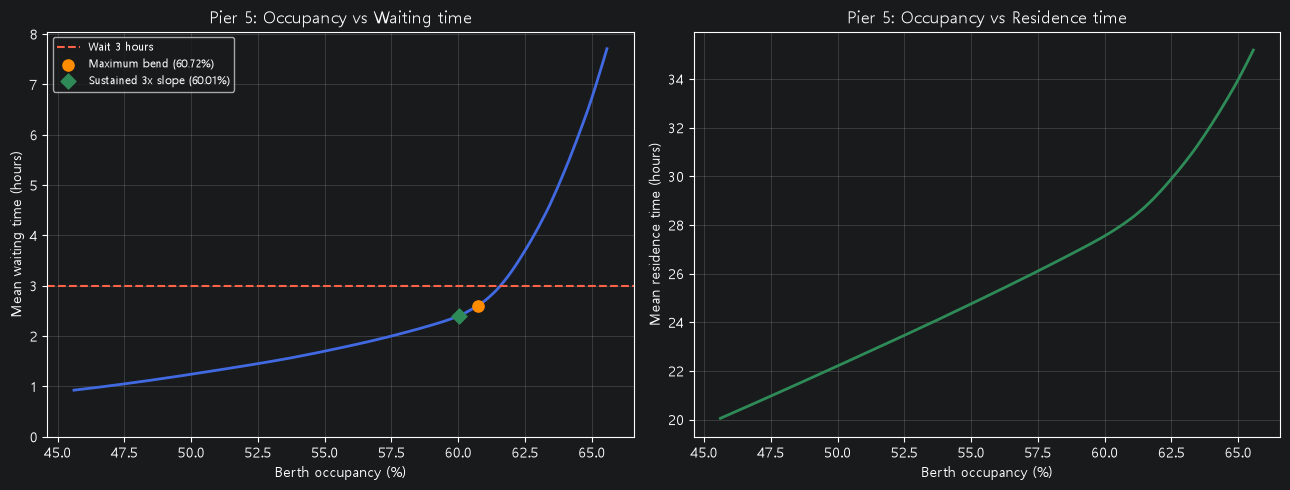

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(results5['점유율'], results5['평균대기시간'],
             color='royalblue', linewidth=2)
axes[0].axhline(3, color='tomato', linestyle='--', label='Wait 3 hours')
axes[0].scatter(x[bend_idx], y[bend_idx], color='darkorange', s=65,
                label=f'Maximum bend ({x[bend_idx]:.2f}%)', zorder=5)
if onset_idx is not None:
    axes[0].scatter(x[onset_idx], y[onset_idx], marker='D', color='seagreen',
                    s=58, label=f'Sustained 3x slope ({x[onset_idx]:.2f}%)', zorder=6)
axes[0].set_title('Pier 5: Occupancy vs Waiting time')
axes[0].set_xlabel('Berth occupancy (%)')
axes[0].set_ylabel('Mean waiting time (hours)')
axes[0].set_ylim(bottom=0)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(results5['점유율'], results5['평균재항시간'],
             color='seagreen', linewidth=2)
axes[1].set_title('Pier 5: Occupancy vs Residence time')
axes[1].set_xlabel('Berth occupancy (%)')
axes[1].set_ylabel('Mean residence time (hours)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---

# 6. 1~5부두 결과 비교

각 부두에서 **원본 데이터를 직접 전처리하고 계산한 결과**를 마지막에 모았습니다. 이 부분도 외부 시뮬레이션 CSV를 읽지 않습니다.

In [49]:
comparison = pd.DataFrame([summary1, summary2, summary3, summary4, summary5])
display(comparison.round(2))

,부두,최종 분석 건수,기본 점유율,최대 굴곡점,기울기 3배 시작점,대기 3시간 도달점
0,1부두,2815,75.79,80.90,78.44,81.87
1,2부두,4576,58.76,62.28,61.55,65.71
2,3부두,1959,25.21,26.60,27.35,NaN
3,4부두,2511,50.81,53.86,54.11,NaN
4,5부두,3349,57.02,60.72,60.01,61.58


## 분석 결과 해석 시 주의할 점

1. **점유율은 모형 점유율**입니다. 원자료 중 매칭에 성공하고 시간 조건을 통과한 선박들만 포함하므로 실제 운영 점유율과 다를 수 있습니다.
2. **2부두:** 터미널 4-9를 PORTMIS 1-6에 대응합니다. 제공된 PORTMIS 6선석 기록이 없으면 최종 시뮬레이션은 연결 가능한 선석만 사용합니다.
3. **3부두:** 역순 선석 대응은 사용자가 선택한 분석 가정이며 실제 선석의 공식 대응 관계로 검증된 것은 아닙니다.
4. **최대 굴곡점**은 특정 구간에서 가장 크게 휘어 보이는 위치를 고르는 수치 규칙이고, **3배 시작점**은 기울기 3배가 5구간 이어지는 첫 위치입니다. 혼잡의 실제 물리적 한계와 동일하지 않습니다.
5. 최초 노트북의 대기시간 3시간 도달점은 별도 지표로 유지했습니다.

그래프를 이미지로 저장하고 싶다면 각 부두 그래프 셀에서 `plt.show()` **앞에** `plt.savefig('pier1.png', dpi=150, bbox_inches='tight')`와 같이 추가하시면 됩니다.